# Лабораторна робота №3

## Оптимізація гіперпараметрів, вкладена крос-валідація та дослідження витоку даних (Data Leakage)

**Дисципліна:** Методологія та процеси моделювання у штучному інтелекті

**Виконав:** Колодійчук Олександр, ст. гр. КНСШ-13

---

**Датасет:** Rain in Australia (weatherAUS), [Kaggle](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package)
Первинне джерело – Australian Bureau of Meteorology.

**Задача:** бінарна класифікація – прогноз опадів на наступну добу (`RainTomorrow`).

Набір даних, конвеєр його підготовки та модель узято з лабораторних робіт №1 і №2.
У ЛР №1 обґрунтовано кожне рішення щодо обробки даних (механізм пропусків MNAR,
IterativeImputer, Yeo-Johnson, Target Encoding із крос-фітингом, хронологічний поділ),
у ЛР №2 порівняно три алгоритми й обрано найкращий. Ця робота продовжує ту саму
лінію: модель із ЛР №2 тепер **налаштовується**, а якість цього налаштування
перевіряється на коректність.

### Структура ноутбука

| Розділ | Зміст | Етап методички |
|---|---|---|
| **0** | Підготовка середовища | – |
| **1** | Дані, модель і протокол оцінювання | Етап 1 |
| **2** | Дослідження 1: Grid vs Random vs Bayesian | Етап 2 |
| **3** | Дослідження 2: вплив витоку даних | Етап 3 |
| **4** | Дослідження 3: вкладена крос-валідація | Етап 4 |
| **5** | Підсумковий звіт і збереження артефактів | Вимоги до звіту |

### Що саме перевіряється в роботі

| Питання | Де відповідь |
|---|---|
| Який метод пошуку дає найкращу якість за найменший час? | Розділи 2.5–2.6 |
| Наскільки витік даних завищує оцінку якості? | Розділи 3.2–3.4 |
| Чи є оцінка з внутрішньої CV чесною? | Розділи 4.3–4.4 |
| Що обрати за обмежених обчислювальних ресурсів? | Розділ 5 і висновки |

Повне виконання ноутбука в Google Colab займає близько 55 хвилин.
Найдовші комірки – 2.2 (повний перебір, близько 10 хв) та 4.2 (вкладена
крос-валідація, близько 33 хв). Решта розділів разом – менш ніж 12 хвилин.
Такий час не є недоліком реалізації: саме обчислювальна вартість підбору
гіперпараметрів і є предметом цієї роботи.


---
# Розділ 0. Підготовка середовища

### Комірка 0.1 – встановлення відсутніх бібліотек

Для байєсівської оптимізації використовуємо **Optuna** – методичка допускає її
або `BayesSearchCV` зі `scikit-optimize`. Вибір на користь Optuna зроблено тому,
що `scikit-optimize` давно не оновлювався й несумісний зі свіжими версіями
scikit-learn, тоді як Optuna підтримується й дає прямий доступ до історії
випробувань, яка знадобиться для графіка збіжності.

Решта бібліотек присутні у стандартному образі Google Colab.

In [1]:
# --- Перевірка та встановлення залежностей ---
# Встановлюємо пакет тільки якщо його немає: це економить час при повторних запусках.
import importlib.util
import subprocess
import sys

for pkg, module in [("optuna", "optuna")]:
    if importlib.util.find_spec(module) is None:
        print(f"Встановлення {pkg} …")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
    else:
        print(f"{pkg}: вже встановлено")


Встановлення optuna …


### Комірка 0.2 – імпорт бібліотек та глобальні константи

Фіксуємо `RANDOM_STATE = 42` – те саме значення, що й у ЛР №1 і ЛР №2. Його
отримують **усі** джерела випадковості: поділ на фолди, підвибірка, ініціалізація
моделі, генератор кандидатів `RandomizedSearchCV` і семплер Optuna. Без цього
порівняння методів оптимізації було б некоректним: різниця між ними могла б
пояснюватися не стратегією пошуку, а різними випадковими послідовностями.

In [2]:
# ========== Стандартні бібліотеки ==========
import json
import shutil
import time
import warnings
from pathlib import Path

# ========== Робота з даними ==========
import numpy as np
import pandas as pd

# ========== Візуалізація ==========
import matplotlib as mpl
import matplotlib.pyplot as plt

# ========== scikit-learn: підготовка даних ==========
# enable_iterative_imputer обов'язково імпортувати ДО IterativeImputer –
# це експериментальний модуль, який без цього рядка недоступний.
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import (PowerTransformer, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from joblib import Memory

# ========== scikit-learn: моделі та пошук гіперпараметрів ==========
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_score,
                                     cross_validate, ParameterGrid)

# ========== scikit-learn: метрики ==========
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, make_scorer)

# ========== Байєсівська оптимізація ==========
import optuna

# ========== Глобальні налаштування ==========
RANDOM_STATE = 42            # єдине зерно випадковості для всієї роботи
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore")        # приховуємо службові попередження бібліотек
optuna.logging.set_verbosity(optuna.logging.WARNING)   # Optuna не друкує кожне випробування

# Налаштування виводу таблиць pandas
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

print("Версії бібліотек:")
print(f"  pandas       {pd.__version__}")
print(f"  numpy        {np.__version__}")
import sklearn
print(f"  scikit-learn {sklearn.__version__}")
print(f"  optuna       {optuna.__version__}")
print(f"\nRANDOM_STATE = {RANDOM_STATE}")


Версії бібліотек:
  pandas       2.2.3
  numpy        2.1.3
  scikit-learn 1.6.1
  optuna       5.0.0

RANDOM_STATE = 42


### Комірка 0.3 – єдина система оформлення графіків

Стиль графіків задаємо централізовано – той самий, що й у ЛР №1 і ЛР №2, щоб
рисунки всіх трьох звітів виглядали однаково:

* **категорійна палітра** – фіксований порядок кольорів, перевірений на розрізнюваність при дальтонізмі;
* **дивергентна шкала** – для величин зі знаком (різниці метрик, завищення через витік);
* **послідовна шкала** – для величин без знака;
* приглушені сітка й осі.

In [3]:
# --- Єдина система оформлення графіків ---

# Категорійна палітра: кольори призначаються у ФІКСОВАНОМУ порядку і ніколи
# не "циклюються". Перевірена на розрізнюваність при дальтонізмі.
PALETTE = ["#2563eb",   # синій        – перша серія
           "#ea580c",   # жовтогарячий – друга серія / погіршення
           "#0d9488",   # бірюзовий    – третя серія / покращення
           "#7c3aed"]   # фіолетовий   – четверта серія

# Різниці метрик мають знак -> ДИВЕРГЕНТНА шкала (два полюси + нейтральна середина).
CMAP_DIV = "RdBu_r"
# Значення метрик знака не мають -> ПОСЛІДОВНА одноколірна шкала.
CMAP_SEQ = "Blues"

INK, MUTED, GRID_C = "#1f2328", "#57606a", "#d8dee4"   # кольори тексту й сітки

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID_C, "axes.labelcolor": INK, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": .6, "grid.alpha": .7,
    "axes.axisbelow": True,                      # сітка ПІД даними, не над ними
    "axes.spines.top": False, "axes.spines.right": False,   # прибираємо зайві рамки
    "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
})

# Сталі кольори методів оптимізації: один метод – один колір на всіх рисунках.
# Словник заповнюється автоматично в міру реєстрації методів (комірка 2.1),
# тож кольори не треба синхронізувати з назвами вручну.
METHOD_COLORS = {}

def method_color(name):
    """Повертає колір методу, призначаючи новий при першому зверненні."""
    if name not in METHOD_COLORS:
        METHOD_COLORS[name] = PALETTE[len(METHOD_COLORS) % len(PALETTE)]
    return METHOD_COLORS[name]

def style_axes(ax, title=None, xlabel=None, ylabel=None):
    """Допоміжна функція: однакове підписування осей для всіх графіків."""
    if title:
        ax.set_title(title, pad=12)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    return ax

print("Стиль графіків налаштовано.")
print("Палітра:", " ".join(PALETTE))


Стиль графіків налаштовано.
Палітра: #2563eb #ea580c #0d9488 #7c3aed


---
# Розділ 1. Дані, модель і протокол оцінювання

**Етап 1 методички:** обрати модель з лабораторної роботи №2 (з високою кількістю
гіперпараметрів або схильну до перенавчання) та зафіксувати метрику якості
відповідно до типу задачі.

Розділ виконує чотири речі:

1. відтворює набір даних і хронологічний поділ вибірки з ЛР №1 та ЛР №2;
2. обґрунтовує вибір моделі та фіксує метрику;
3. переписує конвеєр підготовки даних у вигляді **sklearn-сумісного трансформера** –
   без цього неможливо ані коректно порівняти пайплайни в розділі 3, ані реалізувати
   вкладену крос-валідацію в розділі 4;
4. визначає обчислювальний бюджет і створює baseline-модель, відносно якої
   вимірюватиметься приріст від оптимізації.

### Комірка 1.1 – завантаження датасету

Файл `weatherAUS.csv` має лежати поряд із ноутбуком. У Google Colab, якщо файлу немає,
відкриється діалог вибору файла.

Рядки без значення цільової змінної вилучаємо: заповнювати мітку неприпустимо –
модель навчалася б на вигаданих відповідях. Це те саме рішення, що й у попередніх
двох роботах, тому обсяг робочої вибірки має збігтися з ними.

In [4]:
# --- Завантаження датасету ---
DATA_PATH = Path("weatherAUS.csv")

if not DATA_PATH.exists():
    # У Colab пропонуємо завантажити файл інтерактивно
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "Покладіть weatherAUS.csv у робочу теку ноутбука.\n"
            "Джерело: https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package"
        )

# parse_dates – одразу приводимо стовпець Date до типу datetime64,
# це знадобиться для хронологічного поділу вибірки.
df_raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])

TARGET   = "RainTomorrow"   # цільова змінна (що прогнозуємо)
DATE_COL = "Date"           # службова: лише для хронологічного поділу вибірки

# Рядки без мітки вилучаємо: заповнювати цільову змінну неприпустимо –
# модель навчалася б на вигаданих відповідях.
n_no_label = df_raw[TARGET].isna().sum()
df = df_raw.dropna(subset=[TARGET]).reset_index(drop=True)

# Числові ознаки: всі стовпці числового типу
NUM_FEATURES = df.select_dtypes(include=np.number).columns.tolist()
# Категоріальні: все, що не число, не дата і не цільова змінна
CAT_FEATURES = [c for c in df.columns
                if c not in NUM_FEATURES + [DATE_COL, TARGET]]
FEATURES = NUM_FEATURES + CAT_FEATURES   # повний перелік предикторів

print(f"Сирий файл: {df_raw.shape[0]:,} рядків × {df_raw.shape[1]} стовпців".replace(",", " "))
print(f"Вилучено рядків без мітки: {n_no_label:,}".replace(",", " "))
print(f"Робоча вибірка: {df.shape[0]:,} рядків".replace(",", " "))
print(f"\nЧислових ознак:       {len(NUM_FEATURES)}")
print(f"Категоріальних ознак: {len(CAT_FEATURES)}")
print(f"Разом предикторів:    {len(FEATURES)}")

# Частка позитивного класу – основа для вибору метрики:
# за дисбалансу Accuracy стає нечутливою до рідкісного класу.
share_yes = (df[TARGET] == "Yes").mean() * 100
print(f"\nЧастка класу Yes: {share_yes:.2f} %   "
      f"(дисбаланс 1 : {(100 - share_yes) / share_yes:.2f})")
df.head()


Saving weatherAUS.csv to weatherAUS.csv
Сирий файл: 145 460 рядків × 23 стовпців
Вилучено рядків без мітки: 3 267
Робоча вибірка: 142 193 рядків

Числових ознак:       16
Категоріальних ознак: 5
Разом предикторів:    21

Частка класу Yes: 22.42 %   (дисбаланс 1 : 3.46)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### Комірка 1.2 – хронологічний поділ вибірки

Поділ виконуємо **за часом, а не випадково** – з тих самих міркувань, що й у ЛР №1:
сусідні дні однієї метеостанції сильно корельовані, тому випадковий поділ розкидав
би майже однакові спостереження між навчанням і перевіркою й завищив би оцінку.
По суті це перший, найзагальніший захист від витоку даних, якому присвячено розділ 3.

Межі підібрано так, щоб кожна частина містила повні річні цикли:

* **2007–2015** – навчальна вибірка; саме на ній відбуватиметься вся оптимізація;
* **2016** – валідаційна; незалежна перевірка результатів оптимізації;
* **2017** – тестова; торкаємося її один-єдиний раз, у розділі 5.

In [5]:
# --- Хронологічний поділ вибірки ---
# Виділяємо рік зі стовпця дати – за ним і ділитимемо вибірку
df["year"] = df[DATE_COL].dt.year

# Межі підібрано так, щоб кожна вибірка містила ПОВНІ річні цикли:
# інакше в навчанні переважали б, скажімо, літні місяці, а в тесті – зимові.
train_mask = df["year"] <= 2015      # 2007-2015: навчання та вся оптимізація
valid_mask = df["year"] == 2016      # 2016: незалежна перевірка результатів
test_mask  = df["year"] >= 2017      # 2017: фінальна оцінка, один раз

# .copy() обов'язковий: без нього pandas поверне представлення (view),
# і подальше додавання стовпців спричинить SettingWithCopyWarning.
df_train = df[train_mask].copy()
df_valid = df[valid_mask].copy()
df_test  = df[test_mask].copy()

# Цільова змінна у бінарному вигляді: Yes -> 1, No -> 0.
# Усі метрики класифікації в scikit-learn працюють саме з числовими мітками.
y_train = (df_train[TARGET] == "Yes").astype(int).values
y_valid = (df_valid[TARGET] == "Yes").astype(int).values
y_test  = (df_test[TARGET]  == "Yes").astype(int).values

split_info = pd.DataFrame({
    "Вибірка": ["Навчальна (train)", "Валідаційна (valid)", "Тестова (test)"],
    "Період": ["2007–2015", "2016", "2017"],
    "Рядків": [len(df_train), len(df_valid), len(df_test)],
    "Частка, %": [round(len(x) / len(df) * 100, 1)
                  for x in (df_train, df_valid, df_test)],
    "Частка класу Yes, %": [round(y.mean() * 100, 2)
                            for y in (y_train, y_valid, y_test)],
    "Призначення": ["пошук гіперпараметрів", "перевірка результатів пошуку",
                    "фінальна оцінка (розділ 5)"],
})
display(split_info)

print("Уся крос-валідація розділів 2-4 відбувається ВСЕРЕДИНІ навчальної вибірки.")
print("Валідаційна вибірка 2016 року в підборі гіперпараметрів участі не бере.")
print("Тестова вибірка 2017 року залишається недоторканою до розділу 5.")


,Вибірка,Період,Рядків,"Частка, %","Частка класу Yes, %",Призначення
0,Навчальна (train),2007–2015,116219,81.7,22.31,пошук гіперпараметрів
1,Валідаційна (valid),2016,17508,12.3,23.89,перевірка результатів пошуку
2,Тестова (test),2017,8466,6.0,20.82,фінальна оцінка (розділ 5)


Уся крос-валідація розділів 2-4 відбувається ВСЕРЕДИНІ навчальної вибірки.
Валідаційна вибірка 2016 року в підборі гіперпараметрів участі не бере.
Тестова вибірка 2017 року залишається недоторканою до розділу 5.


### Комірка 1.3 – вибір моделі з ЛР №2 та фіксація метрики

Методичка вимагає взяти модель **з високою кількістю гіперпараметрів або схильну
до перенавчання**. У ЛР №2 порівнювалися три алгоритми, тож вибір робимо не навмання,
а за числами, отриманими в тій роботі.

**Градієнтний бустинг (`HistGradientBoostingClassifier`)** задовольняє обидві умови
одразу й виграє за трьома міркуваннями:

* **кількість гіперпараметрів.** Швидкість навчання, кількість ітерацій, розмір дерева,
  мінімальний розмір листа, L2-регуляризація, частка ознак – простір налаштування
  набагато ширший, ніж у логістичної регресії з фактично одним параметром `C`.
* **схильність до перенавчання.** Бустинг нарощує дерева послідовно, кожне наступне
  виправляє помилки попередніх. Без обмеження кількості ітерацій і розміру дерев він
  доводить помилку на навчальній вибірці майже до нуля. Саме тому його якість так
  сильно залежить від гіперпараметрів – а отже, є що оптимізувати.
* **обчислювальна вартість.** У ЛР №2 випадковий ліс навчався 63,9 с проти 14,8 с у
  бустингу. Пошук гіперпараметрів вимагає сотень навчань, тому різниця в чотири рази
  на одному навчанні перетворюється на різницю в години на всьому експерименті.
  Випадковий ліс за такого бюджету просто не порахувався б у Colab.

Додатковий аргумент: саме бустинг у ЛР №2 став остаточною конфігурацією, тож ця
робота природно продовжує попередню.

**Метрика.** Методичка пропонує F1-score або ROC-AUC. Головною фіксуємо **F1** –
вона безпосередньо залежить від порога, а отже, чутлива до гіперпараметрів, і
водночас враховує обидва типи помилок за дисбалансу класів. ROC-AUC і PR-AUC
рахуємо паралельно як довідкові: вони не залежать від порога й показують, чи
узгоджені висновки між метриками.

In [6]:
# --- Обґрунтування вибору моделі (числа з ЛР №2) ---
# Таблиця відтворює результати попередньої роботи: вона пояснює, ЧОМУ саме
# градієнтний бустинг обрано для оптимізації гіперпараметрів.
lab2_models = pd.DataFrame({
    "Модель": ["Логістична регресія", "Випадковий ліс", "Градієнтний бустинг"],
    "Ключових гіперпараметрів": [2, 5, 6],
    "F1 (валідація 2016)": [0.6066, 0.6109, 0.6496],
    "Розрив F1 (навч. – валід.)": [-0.0013, 0.3376, 0.0610],
    "Час навчання, с": [1.1, 63.9, 14.8],
})
display(lab2_models)

# --- Фіксація моделі та метрики (Етап 1 методички) ---
MODEL_NAME = "HistGradientBoostingClassifier"
PRIMARY_METRIC = "f1"                       # головна метрика оптимізації
SECONDARY_METRICS = ["roc_auc", "pr_auc"]   # довідкові, рахуються паралельно

def make_model(**params):
    """Створює СВІЖИЙ екземпляр моделі із заданими гіперпараметрами.

    early_stopping=False – принципово: вбудоване раннє зупинення відрізало б
    частину навчальної вибірки під власну перевірку і зробило б параметр
    max_iter напівфіктивним, а ми саме його й оптимізуємо.
    """
    base = dict(random_state=RANDOM_STATE, early_stopping=False)
    base.update(params)
    return HistGradientBoostingClassifier(**base)

# Набір оцінювачів для крос-валідації: одним проходом рахуємо всі три метрики.
SCORERS = {
    "f1": make_scorer(f1_score),
    "roc_auc": make_scorer(roc_auc_score, response_method="predict_proba"),
    "pr_auc": make_scorer(average_precision_score, response_method="predict_proba"),
}

print(f"Обрана модель:     {MODEL_NAME}")
print(f"Головна метрика:   F1-score")
print(f"Довідкові метрики: ROC-AUC, PR-AUC")
print(f"\nГіперпараметри за замовчуванням:")
for k, v in make_model().get_params().items():
    if k in ("learning_rate", "max_iter", "max_leaf_nodes",
             "min_samples_leaf", "l2_regularization", "max_features"):
        print(f"  {k:<20} = {v}")


,Модель,Ключових гіперпараметрів,F1 (валідація 2016),Розрив F1 (навч. – валід.),"Час навчання, с"
0,Логістична регресія,2,0.6066,-0.0013,1.1
1,Випадковий ліс,5,0.6109,0.3376,63.9
2,Градієнтний бустинг,6,0.6496,0.0610,14.8


Обрана модель:     HistGradientBoostingClassifier
Головна метрика:   F1-score
Довідкові метрики: ROC-AUC, PR-AUC

Гіперпараметри за замовчуванням:
  l2_regularization    = 0.0
  learning_rate        = 0.1
  max_features         = 1.0
  max_iter             = 100
  max_leaf_nodes       = 31
  min_samples_leaf     = 20


### Комірка 1.4 – конвеєр підготовки даних як sklearn-сумісний трансформер

Це ключова технічна відмінність цієї роботи від попередньої. У ЛР №2 обробка даних
була послідовністю комірок: перетворювачі навчалися один раз на навчальній вибірці,
і матриця ознак існувала як готовий об'єкт. Для ЛР №3 цього недостатньо.

**Чому.** І дослідження витоку (розділ 3), і вкладена крос-валідація (розділ 4)
вимагають, щоб обробка даних **навчалася заново всередині кожного фолда**. Інакше
статистики, обчислені на всій вибірці, потраплять у ті рядки, на яких модель потім
перевіряється, – а це і є витік. Щоб так можна було зробити, увесь конвеєр ЛР №1
треба переписати як один клас із методами `fit` і `transform`, який scikit-learn
вміє вставляти у `Pipeline` й клонувати для кожного фолда.

**Що всередині** (той самий порядок, що й у сценарії Б лабораторної роботи №2):

1. прапорці пропусків для MNAR-ознак – створюються ДО імпутації, бо після неї
   інформація про пропуск зникне;
2. імпутація числових ознак методом IterativeImputer (MICE);
3. степеневе перетворення Yeo-Johnson зі стандартизацією;
4. Target Encoding для `Location` із байєсівським згладжуванням;
5. Frequency Encoding для `Location`;
6. One-Hot для напрямків вітру, Ordinal для `RainToday`.

**Найважливіша деталь – метод `fit_transform`.** Для Target Encoding він навмисне
НЕ дорівнює послідовності `fit` + `transform`. На навчальних рядках коди обчислюються
**out-of-fold**: мітка рядка не бере участі в обчисленні його власного коду. Параметр
`oof_target` дозволяє цей захист вимкнути – у розділі 3 саме так буде відтворено
класичний витік через цільове кодування.

In [7]:
# --- Конвеєр підготовки даних у вигляді sklearn-сумісного трансформера ---

# Ознаки з механізмом MNAR: сам факт пропуску несе інформацію про оснащення станції
MNAR_COLS     = ["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm"]
HIGH_CARD_COL = "Location"                                   # 49 станцій
ONEHOT_COLS   = ["WindGustDir", "WindDir9am", "WindDir3pm"]   # номінальні, 16 румбів
ORDINAL_COLS  = ["RainToday"]                                 # бінарна

# Ключі, за якими можна виконувати цільове кодування. Другий – взаємодія
# станції з місяцем: змістовна ознака ("як часто тут дощить у цю пору року"),
# але категорій у неї в 12 разів більше. У розділі 3 саме ця різниця в
# кардинальності покаже, від чого залежить величина витоку.
TE_KEYS = {
    "Location": lambda X: X[HIGH_CARD_COL].astype(str),
    "LocMonth": lambda X: (X[HIGH_CARD_COL].astype(str) + "_"
                           + X[DATE_COL].dt.month.astype(str)),
}


class WeatherPreprocessor(BaseEstimator, TransformerMixin):
    """Повний конвеєр підготовки даних ЛР №1 як один sklearn-трансформер.

    Параметри
    ---------
    impute : {"mice", "median"}
        Спосіб заповнення пропусків у числових ознаках.
    mice_iter : int
        Кількість раундів IterativeImputer.
    power : bool
        Чи застосовувати перетворення Yeo-Johnson.
    smoothing : int
        Параметр m байєсівського згладжування Target Encoding.
    te_splits : int
        Кількість фолдів крос-фітингу для Target Encoding.
    oof_target : bool
        True  – коди цільового кодування для навчальних рядків обчислюються
                out-of-fold (коректно);
        False – використовуються коди, обчислені на всій навчальній частині
                (класичний витік; застосовується лише в розділі 3).
    te_keys : tuple
        Ключі цільового кодування з довідника TE_KEYS. За замовчуванням –
        лише станція; у розділі 3 додається взаємодія станції з місяцем.
    """

    def __init__(self, impute="mice", mice_iter=5, power=True,
                 smoothing=20, te_splits=5, oof_target=True,
                 te_keys=("Location",)):
        # У sklearn-сумісному класі __init__ лише зберігає параметри:
        # жодних обчислень, інакше clone() ламається.
        self.impute = impute
        self.mice_iter = mice_iter
        self.power = power
        self.smoothing = smoothing
        self.te_splits = te_splits
        self.oof_target = oof_target
        self.te_keys = te_keys

    # ---------- службові ----------
    def _key(self, X, name):
        """Будує Series-ключ цільового кодування за його назвою."""
        return TE_KEYS[name](X)

    def _te_codes(self, cats, y):
        """Коди Target Encoding із байєсівським згладжуванням.

        TE(c) = (n_c * mean_c + m * global_mean) / (n_c + m)

        Що менша категорія, то сильніше її код стягується до глобального
        середнього – це захист від переоцінки рідкісних станцій.
        """
        gm = y.mean()
        st = pd.Series(y, index=cats.index).groupby(cats).agg(["count", "mean"])
        codes = ((st["count"] * st["mean"] + self.smoothing * gm)
                 / (st["count"] + self.smoothing))
        return codes, gm

    def _assemble(self, X, te_values):
        """Збирає підсумкову числову матрицю з уже навчених перетворювачів.

        Блоки ознак складаємо через np.column_stack, а не додаванням
        стовпців до DataFrame по одному: конвеєр викликається сотні разів,
        і поколонне додавання 48 стовпців щоразу копіювало б увесь кадр.
        """
        # 1-2. Числові ознаки: імпутація, потім степеневе перетворення.
        # Саме transform, а не fit_transform – параметри вже вивчено у fit().
        num = self.imputer_.transform(X[NUM_FEATURES])
        if self.power:
            num = self.power_.transform(num)

        # 3. Прапорці пропусків: беремо з СИРОГО кадру, бо після імпутації
        # пропусків уже немає.
        flags = X[MNAR_COLS].isna().to_numpy(dtype=np.float32)

        # 4-5. Цільове кодування (один стовпець на ключ) і частотне кодування.
        te = np.asarray(te_values, dtype=np.float32).reshape(len(X), -1)
        freq = (X[HIGH_CARD_COL].map(self.freq_).fillna(0)
                .to_numpy(dtype=np.float32).reshape(-1, 1))

        # 6. Напрямки вітру -> One-Hot, RainToday -> 0/1.
        oh = self.ohe_.transform(X[ONEHOT_COLS].fillna("Unknown"))
        rt = self.ord_.transform(X[ORDINAL_COLS].fillna("No"))

        # float32 замість float64 удвічі зменшує обсяг пам'яті
        # без помітної втрати точності для цих даних.
        return np.column_stack([num, flags, te, freq, oh, rt]).astype(np.float32)

    # ---------- sklearn API ----------
    def fit(self, X, y=None):
        """Навчає всі перетворювачі НА ПЕРЕДАНИХ рядках і тільки на них."""
        # Імпутація числових ознак
        self.imputer_ = (IterativeImputer(max_iter=self.mice_iter,
                                          random_state=RANDOM_STATE)
                         if self.impute == "mice"
                         else SimpleImputer(strategy="median"))
        self.imputer_.fit(X[NUM_FEATURES])

        # Степеневе перетворення навчаємо вже на заповнених даних
        if self.power:
            self.power_ = PowerTransformer(method="yeo-johnson", standardize=True)
            self.power_.fit(self.imputer_.transform(X[NUM_FEATURES]))

        # handle_unknown="ignore" – небачена категорія дасть рядок нулів,
        # а не помилку під час перевірки на іншому фолді.
        self.ohe_ = OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                  dtype=np.float32)
        self.ohe_.fit(X[ONEHOT_COLS].fillna("Unknown"))
        self.ohe_names_ = self.ohe_.get_feature_names_out(ONEHOT_COLS).tolist()

        # Порядок категорій задаємо явно, щоб не залежати від сортування.
        self.ord_ = OrdinalEncoder(categories=[["No", "Yes"]],
                                   handle_unknown="use_encoded_value",
                                   unknown_value=-1)
        self.ord_.fit(X[ORDINAL_COLS].fillna("No"))

        # Частотне кодування: частка спостережень станції серед переданих рядків
        self.freq_ = X[HIGH_CARD_COL].value_counts(normalize=True)

        # Цільове кодування потребує міток; коди рахуємо для кожного ключа
        if y is not None:
            self.te_map_, self.te_gm_ = {}, {}
            for k in self.te_keys:
                self.te_map_[k], self.te_gm_[k] = self._te_codes(self._key(X, k),
                                                                 np.asarray(y))
        return self

    def transform(self, X):
        """Застосовує навчені перетворення. Мітки НЕ потрібні й не використовуються."""
        te = np.column_stack([
            self._key(X, k).map(self.te_map_[k]).fillna(self.te_gm_[k]).values
            for k in self.te_keys])
        return self._assemble(X, te)

    def fit_transform(self, X, y=None):
        """Навчання і перетворення НАВЧАЛЬНИХ рядків.

        Відрізняється від fit().transform() цільовим кодуванням: за
        oof_target=True коди обчислюються out-of-fold, тож мітка рядка не
        впливає на його власний код. Саме це робить Target Encoding безпечним.
        """
        self.fit(X, y)
        if y is None or not self.oof_target:
            # Витік: рядок кодується статистикою, в яку входить його власна мітка
            return self.transform(X)

        y = np.asarray(y)
        kf = KFold(n_splits=self.te_splits, shuffle=True, random_state=RANDOM_STATE)
        cols = []
        for k in self.te_keys:
            cats = self._key(X, k)
            oof = np.full(len(X), np.nan)
            for tr_idx, va_idx in kf.split(cats):
                # Статистики рахуємо на tr_idx, а ЗАСТОСОВУЄМО до va_idx
                codes, gm = self._te_codes(cats.iloc[tr_idx], y[tr_idx])
                # fillna(gm): категорія могла не трапитися в цьому фолді – тоді
                # підставляємо середнє цього ж фолду, а не глобальне.
                oof[va_idx] = cats.iloc[va_idx].map(codes).fillna(gm).values
            cols.append(oof)
        return self._assemble(X, np.column_stack(cols))

    def feature_names(self):
        """Імена стовпців підсумкової матриці – для інтерпретації результатів."""
        return (NUM_FEATURES
                + [f"{c}_missing" for c in MNAR_COLS]
                + [f"{k}_te" for k in self.te_keys] + ["Location_freq"]
                + self.ohe_names_ + ["RainToday"])


print("Клас WeatherPreprocessor визначено.")
print("Склад конвеєра: прапорці MNAR -> MICE -> Yeo-Johnson -> "
      "Target/Frequency Encoding -> One-Hot -> Ordinal")


Клас WeatherPreprocessor визначено.
Склад конвеєра: прапорці MNAR -> MICE -> Yeo-Johnson -> Target/Frequency Encoding -> One-Hot -> Ordinal


### Комірка 1.5 – перевірка конвеєра

Перш ніж будувати на трансформері всі подальші експерименти, переконуємося, що він
відтворює результат ЛР №2: та сама кількість ознак, жодного пропуску в матриці,
коректна робота на небачених даних валідаційної вибірки.

Окремо перевіряємо головну властивість, заради якої клас і писався: `fit_transform`
та `fit` + `transform` на тих самих рядках мають дати **різні** коди цільового
кодування. Якщо різниці немає, крос-фітинг не працює, і весь розділ 3 втратив би сенс.

In [8]:
# --- Перевірка конвеєра на навчальній і валідаційній вибірках ---
t0 = time.time()
prep_check = WeatherPreprocessor()
Z_train = prep_check.fit_transform(df_train, y_train)   # навчання + OOF-кодування
Z_valid = prep_check.transform(df_valid)                # лише застосування
t_prep = time.time() - t0

feat_names = prep_check.feature_names()

print(f"Конвеєр відпрацював за {t_prep:.1f} с")
print(f"  Навчальна матриця:   {Z_train.shape[0]:,} × {Z_train.shape[1]}".replace(",", " "))
print(f"  Валідаційна матриця: {Z_valid.shape[0]:,} × {Z_valid.shape[1]}".replace(",", " "))
print(f"  Пропусків у матрицях: {np.isnan(Z_train).sum() + np.isnan(Z_valid).sum()}")
print(f"  Імен ознак: {len(feat_names)}")
print(f"\nСклад: {len(NUM_FEATURES)} числових + {len(MNAR_COLS)} прапорців "
      f"+ 2 кодування Location + {len(prep_check.ohe_names_)} One-Hot + 1 Ordinal")

# --- Перевірка крос-фітингу Target Encoding ---
# fit_transform має дати ІНШІ коди, ніж fit + transform: у першому випадку
# мітка рядка не бере участі в обчисленні його власного коду.
te_col = feat_names.index("Location_te")
te_oof  = Z_train[:, te_col]
te_full = prep_check.transform(df_train)[:, te_col]
diff = np.abs(te_oof - te_full)

print(f"\nПеревірка крос-фітингу Target Encoding:")
print(f"  Середня різниця кодів OOF і повних: {diff.mean():.5f}")
print(f"  Максимальна різниця:                {diff.max():.5f}")
print(f"  Крос-фітинг працює: {'так' if diff.mean() > 0 else 'НІ – помилка!'}")


Конвеєр відпрацював за 22.3 с
  Навчальна матриця:   116 219 × 74
  Валідаційна матриця: 17 508 × 74
  Пропусків у матрицях: 0
  Імен ознак: 74

Склад: 16 числових + 4 прапорців + 2 кодування Location + 51 One-Hot + 1 Ordinal

Перевірка крос-фітингу Target Encoding:
  Середня різниця кодів OOF і повних: 0.00328
  Максимальна різниця:                0.01132
  Крос-фітинг працює: так


### Комірка 1.6 – обчислювальний бюджет і підвибірка

Оптимізація гіперпараметрів відрізняється від усього, що робилося в попередніх
роботах, однією властивістю: модель навчається не один раз, а сотні разів.
Повний перебір на 54 комбінаціях із трифолдовою внутрішньою крос-валідацією – це
162 навчання; вкладена крос-валідація множить це ще на п'ять зовнішніх фолдів.
Разом за всіма експериментами роботи виходить понад дві тисячі навчань.

Тому перед запуском треба **чесно порахувати бюджет**. Комірка вимірює на поточній
машині дві різні величини – вартість підготовки даних і вартість навчання моделі –
і множить кожну на її власну кількість повторень. Розділяти їх необхідно, бо
масштабуються вони по-різному: обробка виконується раз на фолд, а модель –
на кожну комбінацію гіперпараметрів. За отриманою оцінкою й добираємо обсяг
підвибірок так, щоб ноутбук виконувався за прийнятний час у Google Colab.

**Що саме зменшується і чому це коректно.** Зменшується тільки кількість рядків,
на яких шукаються гіперпараметри, – не кількість ознак, не склад конвеєра, не
протокол оцінювання. Підвибірка стратифікована, тобто зберігає співвідношення класів.
Остаточна модель у розділі 5 навчається на **повній** навчальній вибірці, а
перевіряється на незайманому 2017 році. Такий компроміс – типова практика:
гіперпараметри зазвичай слабко залежать від обсягу даних, тоді як вартість пошуку
залежить від нього прямо.

Для вкладеної крос-валідації беремо меншу підвибірку, ніж для звичайного пошуку:
вона вимагає у п'ять разів більше навчань при тому самому бюджеті.

In [9]:
# --- Обчислювальний бюджет ---
# Міряємо вартість ОДНОГО навчання на поточній машині, щоб оцінки часу
# нижче були не теоретичними, а реальними для цього середовища.
def stratified_subsample(frame, y, n, seed=RANDOM_STATE):
    """Стратифікована підвибірка: зберігає співвідношення класів."""
    rng = np.random.RandomState(seed)
    idx = []
    for cls in np.unique(y):
        pool = np.where(y == cls)[0]
        take = int(round(n * len(pool) / len(y)))     # частка класу зберігається
        idx.append(rng.choice(pool, min(take, len(pool)), replace=False))
    idx = np.sort(np.concatenate(idx))
    return frame.iloc[idx], y[idx]

# Обсяги підвибірок (підібрані за замірами нижче)
N_OPT    = 12000   # розділи 2-3: однорівневий пошук
N_NESTED = 3000    # розділ 4: вкладена CV – у 5 разів більше навчань

X_opt, y_opt = stratified_subsample(df_train, y_train, N_OPT)
X_nst, y_nst = stratified_subsample(df_train, y_train, N_NESTED)

# Вартість розкладаємо на дві частини, бо вони масштабуються по-різному:
# обробка виконується ОДИН раз на фолд, модель – на кожну комбінацію.
X_probe, y_probe = stratified_subsample(df_train, y_train, int(N_OPT * 2 / 3))

t0 = time.time()
Z_probe = WeatherPreprocessor().fit_transform(X_probe, y_probe)
t_prep_fold = time.time() - t0

t0 = time.time()
make_model(max_iter=200, max_leaf_nodes=31).fit(Z_probe, y_probe)
t_model_fit = time.time() - t0

# Бюджети методів пошуку (повний опис простору – комірка 1.8).
# Тримаємо їх тут, щоб оцінка часу рахувалася з тих самих чисел,
# якими пошук виконуватиметься насправді.
N_GRID, N_RND1, N_RND2, N_BAYES = 108, 20, 50, 20
# Кількість фолдів обох петель задає методичка: внутрішня 3, зовнішня 5
K_IN, K_OUT = 3, 5

budget = pd.DataFrame({
    "Експеримент": [f"Повний перебір, {N_GRID} комбінацій (2.2)",
                    f"Випадковий пошук N={N_RND1} (2.3)",
                    f"Випадковий пошук N={N_RND2} (2.3)",
                    f"Байєсівська оптимізація N={N_BAYES} (2.4)",
                    "Дослідження витоку (розділ 3)",
                    "Вкладена крос-валідація (розділ 4)"],
    "Навчань моделі": [N_GRID * K_IN, N_RND1 * K_IN, N_RND2 * K_IN,
                       N_BAYES * K_IN, 8 * K_IN,
                       K_OUT * (N_GRID + N_RND1 + N_RND2 + N_BAYES) * K_IN],
    "Обробок даних": [K_IN, K_IN, K_IN, K_IN, 2 * K_IN, K_OUT * K_IN],
})
# Вкладена CV працює на меншій підвибірці -> масштабуємо вартість лінійно
scale = np.where(budget["Експеримент"].str.contains("Вкладена"), N_NESTED / N_OPT, 1.0)
budget["Оцінка часу, хв"] = ((budget["Навчань моделі"] * t_model_fit
                              + budget["Обробок даних"] * t_prep_fold)
                             * scale / 60).round(1)
display(budget)

print(f"Вартість однієї обробки даних: {t_prep_fold:.2f} с")
print(f"Вартість одного навчання моделі: {t_model_fit:.2f} с   "
      f"(на {len(X_probe):,} рядках)".replace(",", " "))
print(f"Усього навчань за роботу: {budget['Навчань моделі'].sum():,}".replace(",", " "))
print(f"Сумарна оцінка часу: {budget['Оцінка часу, хв'].sum():.0f} хв")
print("\nОбробок даних набагато менше, ніж навчань моделі: обробка не залежить")
print("від гіперпараметрів, тому обчислюється раз на фолд і кешується (комірка 1.7).")
print(f"\nПідвибірка для пошуку (розділи 2-3): {len(X_opt):,} рядків, "
      f"частка класу Yes {y_opt.mean() * 100:.2f} %".replace(",", " "))
print(f"Підвибірка для вкладеної CV (розділ 4): {len(X_nst):,} рядків, "
      f"частка класу Yes {y_nst.mean() * 100:.2f} %".replace(",", " "))
print(f"Для порівняння, повна навчальна вибірка: {len(df_train):,} рядків, "
      f"{y_train.mean() * 100:.2f} %".replace(",", " "))


,Експеримент,Навчань моделі,Обробок даних,"Оцінка часу, хв"
0,"Повний перебір, 108 комбінацій (2.2)",324,3,10.5
1,Випадковий пошук N=20 (2.3),60,3,2.0
2,Випадковий пошук N=50 (2.3),150,3,4.9
3,Байєсівська оптимізація N=20 (2.4),60,3,2.0
4,Дослідження витоку (розділ 3),24,6,0.9
5,Вкладена крос-валідація (розділ 4),2970,15,23.9


Вартість однієї обробки даних: 0.94 с
Вартість одного навчання моделі: 1.93 с   (на 8 000 рядках)
Усього навчань за роботу: 3 588
Сумарна оцінка часу: 44 хв

Обробок даних набагато менше, ніж навчань моделі: обробка не залежить
від гіперпараметрів, тому обчислюється раз на фолд і кешується (комірка 1.7).

Підвибірка для пошуку (розділи 2-3): 12 000 рядків  частка класу Yes 22.31 %
Підвибірка для вкладеної CV (розділ 4): 3 000 рядків  частка класу Yes 22.30 %
Для порівняння  повна навчальна вибірка: 116 219 рядків  22.31 %


### Комірка 1.7 – baseline-модель

Завершальна вимога першого етапу: створити базову модель, відносно якої
вимірюватиметься приріст від оптимізації. Беремо гіперпараметри **за замовчуванням**
і той самий протокол оцінювання, що й у всіх подальших пошуках: трифолдова
стратифікована крос-валідація всередині навчальної вибірки.

Та сама модель одразу перевіряється на валідаційній вибірці 2016 року. Два числа –
оцінка з крос-валідації й оцінка на незалежному році – знадобляться в розділі 4:
різниця між ними показує, наскільки взагалі можна довіряти внутрішній оцінці.

Протокол крос-валідації фіксуємо один раз і більше не змінюємо: **однакові фолди для
всіх методів пошуку**. Інакше різниця між Grid і Random пояснювалася б різними
розбиттями, а не якістю стратегії.

**Кешування обробки даних.** Комірка 1.6 показала, що значну частку вартості одного
навчання становить не модель, а підготовка даних. Водночас обробка **не залежить від
гіперпараметрів моделі**: усі 54 комбінації сітки обробляють той самий фолд однаково.
Тому `Pipeline` отримує параметр `memory` – результат кроку обробки обчислюється один
раз на фолд і далі береться з кешу.

Чи не створює це витоку? Ні, і це важливо розуміти. Ключ кешу містить і параметри
перетворювача, і **самі рядки**, на яких його навчають. Обробка, навчена на одному
фолді, ніколи не буде підставлена іншому: інший фолд – інший ключ – інше обчислення.
Кеш економить повторення тотожних обчислень, а не підміняє дані.

Побічний ефект – виміряний час перестає включати обробку й починає відображати саме
вартість стратегії пошуку. Щоб усі методи були в однакових умовах, кеш **прогріваємо**
заздалегідь: обчислення baseline у цій комірці вже проходить по тих самих трьох
фолдах, тож до розділу 2 кеш уже заповнений.

In [10]:
# --- Протокол крос-валідації: однаковий для ВСІХ експериментів роботи ---
# shuffle=True обов'язковий: дані впорядковані за датою і станцією, тож без
# перемішування фолди отримали б різні станції та різні сезони.
INNER_CV = StratifiedKFold(n_splits=K_IN, shuffle=True, random_state=RANDOM_STATE)
OUTER_CV = StratifiedKFold(n_splits=K_OUT, shuffle=True, random_state=RANDOM_STATE)

# --- Кеш кроку обробки даних ---
# Обробка не залежить від гіперпараметрів моделі, тому в межах одного пошуку
# вона тотожна для всіх кандидатів на даному фолді. Ключ кешу містить і
# параметри перетворювача, і самі рядки, тож обробка одного фолда НІКОЛИ
# не підставляється іншому – витоку кеш не створює.
CACHE_DIR = Path("pipeline_cache")
PREP_CACHE = Memory(location=str(CACHE_DIR), verbose=0)
PREP_CACHE.clear(warn=False)      # починаємо з порожнього кешу при кожному запуску

def make_pipeline(**model_params):
    """Коректний пайплайн: обробка даних і модель як одне ціле.

    Ключова властивість – обробка навчається ВСЕРЕДИНІ кожного фолда,
    бо Pipeline викликає prep.fit_transform лише на навчальній частині.
    """
    return Pipeline([("prep", WeatherPreprocessor()),
                     ("model", make_model(**model_params))],
                    memory=PREP_CACHE)

# --- Baseline: гіперпараметри за замовчуванням ---
# Цей виклик заразом ПРОГРІВАЄ кеш: він проходить по тих самих трьох фолдах,
# що й усі подальші пошуки, тож далі всі методи стартують в однакових умовах.
t0 = time.time()
baseline_cv = cross_validate(make_pipeline(), X_opt, y_opt,
                             scoring=SCORERS, cv=INNER_CV, n_jobs=1,
                             return_train_score=True)
t_baseline = time.time() - t0

BASELINE_F1 = baseline_cv["test_f1"].mean()

# Та сама модель на незалежній валідаційній вибірці 2016 року
base_fitted = make_pipeline().fit(X_opt, y_opt)
proba_valid = base_fitted.predict_proba(df_valid)[:, 1]
pred_valid = (proba_valid >= 0.5).astype(int)
BASELINE_VALID_F1 = f1_score(y_valid, pred_valid)

baseline_tbl = pd.DataFrame({
    "Метрика": ["F1", "ROC-AUC", "PR-AUC"],
    "Крос-валідація (навчання)": [baseline_cv["train_f1"].mean(),
                                  baseline_cv["train_roc_auc"].mean(),
                                  baseline_cv["train_pr_auc"].mean()],
    "Крос-валідація (перевірка)": [baseline_cv["test_f1"].mean(),
                                   baseline_cv["test_roc_auc"].mean(),
                                   baseline_cv["test_pr_auc"].mean()],
    "Розкид по фолдах (±)": [baseline_cv["test_f1"].std(),
                             baseline_cv["test_roc_auc"].std(),
                             baseline_cv["test_pr_auc"].std()],
    "Валідація 2016": [BASELINE_VALID_F1,
                       roc_auc_score(y_valid, proba_valid),
                       average_precision_score(y_valid, proba_valid)],
}).round(4)
display(baseline_tbl)

print(f"Baseline обчислено за {t_baseline:.1f} с")
print(f"Гіперпараметри: за замовчуванням")
print(f"\nF1 (внутрішня крос-валідація): {BASELINE_F1:.4f}")
print(f"F1 (валідація 2016):           {BASELINE_VALID_F1:.4f}")
print(f"Розрив навчання – перевірка:   "
      f"{baseline_cv['train_f1'].mean() - baseline_cv['test_f1'].mean():.4f}")
print(f"\nКеш обробки прогріто: {len(list(CACHE_DIR.rglob('output.pkl')))} записів "
      f"(фолди внутрішньої крос-валідації та повна підвибірка)")
print("\nЦе точка відліку: приріст усіх методів оптимізації міряємо від неї.")


,Метрика,Крос-валідація (навчання),Крос-валідація (перевірка),Розкид по фолдах (±),Валідація 2016
0,F1,0.8390,0.6073,0.0145,0.6123
1,ROC-AUC,0.9838,0.8724,0.0063,0.8588
2,PR-AUC,0.9494,0.7050,0.0145,0.7093


Baseline обчислено за 9.8 с
Гіперпараметри: за замовчуванням

F1 (внутрішня крос-валідація): 0.6073
F1 (валідація 2016):           0.6123
Розрив навчання – перевірка:   0.2317

Кеш обробки прогріто: 4 записів (фолди внутрішньої крос-валідації та повна підвибірка)

Це точка відліку: приріст усіх методів оптимізації міряємо від неї.


### Комірка 1.8 – простір гіперпараметрів

Методичка вимагає простір **не менше 3–4 параметрів**. Беремо чотири, кожен із яких
керує окремим джерелом гнучкості моделі:

| Параметр | За що відповідає | Значення |
|---|---|---|
| `learning_rate` | внесок кожного дерева; менший крок потребує більше дерев | 0,05 / 0,1 / 0,2 |
| `max_iter` | кількість дерев – головний важіль ємності бустингу | 50 / 100 / 200 |
| `max_leaf_nodes` | складність одного дерева, глибина взаємодій ознак | 15 / 31 / 63 |
| `min_samples_leaf` | мінімальний розмір листа – пряма регуляризація | 20 / 50 |
| `l2_regularization` | штраф на величину листків – друга регуляризація | 0 / 1 |

Перші два параметри пов'язані між собою: повільніше навчання з більшою кількістю
дерев зазвичай узагальнює краще, ніж швидке з малою. Саме такі залежності й робить
повний перебір дорогим, а випадковий та байєсівський пошук – цікавими.

Повний перебір дає 3 × 3 × 3 × 2 × 2 = **108 комбінацій**. Розмір простору обрано
навмисно більшим за найбільший бюджет випадкового пошуку. Якби комбінацій було,
скажімо, 54, то `RandomizedSearchCV` з N = 50 переглянув би 93 % простору й
фактично перетворився б на повний перебір – порівняння втратило б сенс. За 108
комбінацій бюджети 20 і 50 покривають 19 % і 46 % простору, тобто лишаються
справжніми вибірками.

Grid Search при цьому перебирає весь простір, тож його результат є **верхньою
межею**, до якої можуть дотягнутися інші методи за менший бюджет.

Для випадкового та байєсівського пошуку задаємо **той самий** простір. Це
принципово: якби розподіли були ширшими, перевага чи програш пояснювалися б
простором, а не стратегією.

In [11]:
# --- Простір гіперпараметрів (Етап 2 методички: не менше 3-4 параметрів) ---
# Сітка для повного перебору
PARAM_GRID = {
    "model__learning_rate":     [0.05, 0.1, 0.2],  # внесок одного дерева
    "model__max_iter":          [50, 100, 200],    # кількість дерев
    "model__max_leaf_nodes":    [15, 31, 63],      # складність дерева
    "model__min_samples_leaf":  [20, 50],          # мінімальний розмір листа
    "model__l2_regularization": [0.0, 1.0],        # штраф на величину листків
}

# Той самий простір для випадкового пошуку: значення беруться з тих самих
# списків, тож різниця між методами пояснюється лише стратегією вибору.
PARAM_DIST = {k: v for k, v in PARAM_GRID.items()}

# Опис простору для Optuna у вигляді (назва, список значень).
# suggest_categorical із тими самими списками гарантує однаковий простір.
OPTUNA_SPACE = [(k.replace("model__", ""), v) for k, v in PARAM_GRID.items()]

GRID_SIZE = len(list(ParameterGrid(PARAM_GRID)))

space_tbl = pd.DataFrame({
    "Гіперпараметр": [k.replace("model__", "") for k in PARAM_GRID],
    "Значення": [", ".join(map(str, v)) for v in PARAM_GRID.values()],
    "Варіантів": [len(v) for v in PARAM_GRID.values()],
    "За що відповідає": ["внесок кожного дерева",
                         "кількість дерев (ємність моделі)",
                         "складність одного дерева",
                         "мінімальний розмір листа (регуляризація)",
                         "штраф на величину листків (регуляризація)"],
})
display(space_tbl)

# Перевірка узгодженості з оцінкою бюджету в комірці 1.6
assert GRID_SIZE == N_GRID, "Розмір сітки розійшовся з оцінкою бюджету"

print(f"Розмір повного простору: "
      f"{' × '.join(str(len(v)) for v in PARAM_GRID.values())} = {GRID_SIZE} комбінацій")
print(f"Бюджети методів: Grid {GRID_SIZE}, Random {N_RND1} і {N_RND2}, "
      f"Bayesian {N_BAYES}")
print(f"Внутрішня крос-валідація: {INNER_CV.get_n_splits()} фолди")
print(f"Отже навчань: Grid {GRID_SIZE * 3}, Random {N_RND1 * 3} і {N_RND2 * 3}, "
      f"Bayesian {N_BAYES * 3}")
print(f"\nЧастка простору, яку переглядає кожен бюджет: "
      f"Random {N_RND1} -> {N_RND1 / GRID_SIZE * 100:.0f} %, "
      f"Random {N_RND2} -> {N_RND2 / GRID_SIZE * 100:.0f} %, "
      f"Bayesian {N_BAYES} -> {N_BAYES / GRID_SIZE * 100:.0f} %")


,Гіперпараметр,Значення,Варіантів,За що відповідає
0,learning_rate,"0.05, 0.1, 0.2",3,внесок кожного дерева
1,max_iter,"50, 100, 200",3,кількість дерев (ємність моделі)
2,max_leaf_nodes,"15, 31, 63",3,складність одного дерева
3,min_samples_leaf,"20, 50",2,мінімальний розмір листа (регуляризація)
4,l2_regularization,"0.0, 1.0",2,штраф на величину листків (регуляризація)


Розмір повного простору: 3 × 3 × 3 × 2 × 2 = 108 комбінацій
Бюджети методів: Grid 108, Random 20 і 50, Bayesian 20
Внутрішня крос-валідація: 3 фолди
Отже навчань: Grid 324, Random 60 і 150, Bayesian 60

Частка простору, яку переглядає кожен бюджет: Random 20 -> 19 %, Random 50 -> 46 %, Bayesian 20 -> 19 %


---
# Розділ 2. Дослідження 1: порівняння методів оптимізації

**Етап 2 методички:** провести оптимізацію трьома методами – повним перебором,
випадковим пошуком із N = {20, 50} ітераціями та байєсівською оптимізацією з
N = 20 ітераціями; зафіксувати час виконання кожної стратегії та найкраще
значення валідаційної метрики.

Три методи розв'язують одну задачу, але по-різному розпоряджаються бюджетом:

* **Grid Search** перебирає всі комбінації. Гарантує, що найкраща точка простору
  знайдена, але вартість зростає як добуток кількості значень усіх параметрів.
* **Random Search** бере випадкові точки простору. Не гарантує нічого, проте на
  практиці швидко знаходить майже найкраще: більшість гіперпараметрів майже не
  впливають на результат, і перебирати їхні комбінації – марна трата бюджету.
* **Bayesian Optimization** будує ймовірнісну модель залежності «гіперпараметри →
  якість» за вже обчисленими точками й обирає наступну точку там, де очікуваний
  виграш найбільший. На відміну від перших двох, кожне наступне випробування
  враховує результати попередніх.

Усі три працюють на **однакових фолдах**, в **однаковому просторі** й з
**однаковим зерном випадковості**, тож різниця в результатах пояснюється лише
стратегією пошуку.

### Комірка 2.1 – допоміжна функція для запуску й обліку пошуку

Щоб порівняння було коректним, усі чотири запуски мають вимірюватися однаково.
Функція нижче фіксує три речі: час виконання, найкраще значення метрики та
**історію** – послідовність оцінок у тому порядку, в якому метод їх обчислював.
Історія знадобиться для графіка збіжності в комірці 2.7.

Важлива деталь: `refit=False`. Після пошуку scikit-learn за замовчуванням ще раз
навчає найкращу модель на всіх даних, і цей час потрапив би у вимір. Нас цікавить
вартість самого пошуку, тому фінальне навчання виконуємо окремо, поза таймером.

`n_jobs=1` теж обрано свідомо: градієнтний бустинг усередині вже використовує всі
ядра процесора. Паралелізація ще й по фолдах призвела б до конкуренції потоків,
і виміряний час залежав би від випадкового планування, а не від стратегії.

In [12]:
# --- Єдиний облік результатів усіх методів оптимізації ---
SEARCH_RESULTS = {}      # назва методу -> словник із результатами

def register_search(name, elapsed, n_evals, best_score, best_params, history,
                    secondary=None):
    """Записує результат одного методу пошуку в спільний реєстр.

    history – послідовність значень метрики в порядку обчислення; саме з неї
    будується крива збіжності «найкраще на поточний момент».
    """
    history = np.asarray(history, dtype=float)
    method_color(name)          # закріплюємо за методом колір для всіх рисунків
    # Зберігаємо все, що знадобиться далі: таблиці розділу 2, криві збіжності
    # комірки 2.7 і заповнення стовпця незміщеної оцінки в розділі 4.
    SEARCH_RESULTS[name] = {
        "Час, с": elapsed,
        "Оцінок": n_evals,
        "Best Score (Inner CV)": best_score,
        "Найкращі гіперпараметри": best_params,
        "Історія": history,
        # np.maximum.accumulate: найкраще значення на кожному кроці пошуку
        "Збіжність": np.maximum.accumulate(history),
        "Довідкові метрики": secondary or {},
    }
    print(f"{name}")
    print(f"  Оцінок:      {n_evals}")
    print(f"  Час:         {elapsed:.1f} с  ({elapsed / n_evals:.2f} с на оцінку)")
    print(f"  Best F1:     {best_score:.4f}   (baseline {BASELINE_F1:.4f}, "
          f"приріст {best_score - BASELINE_F1:+.4f})")
    print(f"  Параметри:   " +
          ", ".join(f"{k.replace('model__', '')}={v}"
                    for k, v in sorted(best_params.items())))


def best_from_cv_results(cv_results):
    """Дістає найкращий результат із cv_results_ без повторного навчання.

    Потрібна окрема функція, бо за refit=False і кількох метрик scikit-learn
    не заповнює best_score_ і best_params_.
    """
    res = pd.DataFrame(cv_results)
    i = res["mean_test_f1"].idxmax()          # рядок із найкращим середнім F1
    # Довідкові метрики беремо з ТОГО САМОГО рядка: це метрики переможця,
    # а не найкращі значення кожної метрики окремо.
    secondary = {m: res.loc[i, f"mean_test_{m}"] for m in SECONDARY_METRICS}
    # Повертаємо також увесь стовпець mean_test_f1 – це й є історія пошуку
    # в порядку обчислення комбінацій.
    return res.loc[i, "mean_test_f1"], res.loc[i, "params"], \
        res["mean_test_f1"].values, secondary

print("Реєстр результатів пошуку створено.")
print(f"Точка відліку (baseline F1): {BASELINE_F1:.4f}")


Реєстр результатів пошуку створено.
Точка відліку (baseline F1): 0.6073


### Комірка 2.2 – Full Grid Search

Повний перебір обчислює метрику для кожної з 54 комбінацій простору. Це єдиний із
трьох методів, який дає **гарантію**: краща точка в межах заданої сітки знайдена
напевно. Ціна гарантії – вартість, що зростає як добуток: додавання п'ятого
параметра з трьома значеннями втричі збільшило б час.

Саме тому результат Grid Search слугує **еталоном** для решти методів: якщо
випадковий пошук за 20 оцінок дотягується до тієї самої якості, це означає, що
решта 34 комбінації перебиралися даремно.

In [13]:
# --- Метод 1: повний перебір (GridSearchCV) ---
# refit=False – фінальне навчання найкращої моделі робимо окремо, щоб воно
# не потрапило у вимір часу пошуку.
grid_search = GridSearchCV(
    estimator=make_pipeline(),
    param_grid=PARAM_GRID,
    scoring=SCORERS,          # усі три метрики за один прохід
    refit=False,
    cv=INNER_CV,
    n_jobs=1,                 # модель уже використовує всі ядра всередині
    verbose=0,
)

t0 = time.time()
grid_search.fit(X_opt, y_opt)
t_grid = time.time() - t0

score, params, hist, sec = best_from_cv_results(grid_search.cv_results_)
register_search("Grid Search", t_grid, GRID_SIZE, score, params, hist, sec)

# Розподіл якості по всьому простору: показує, наскільки взагалі
# результат чутливий до гіперпараметрів.
print(f"\nРозподіл F1 по всіх {GRID_SIZE} комбінаціях:")
print(f"  найгірша:  {hist.min():.4f}")
print(f"  медіана:   {np.median(hist):.4f}")
print(f"  найкраща:  {hist.max():.4f}")
print(f"  розмах:    {hist.max() - hist.min():.4f}")
print(f"\nКомбінацій, що перевершили baseline: "
      f"{(hist > BASELINE_F1).sum()} з {GRID_SIZE}")


Grid Search
  Оцінок:      108
  Час:         577.1 с  (5.34 с на оцінку)
  Best F1:     0.6219   (baseline 0.6073, приріст +0.0147)
  Параметри:   l2_regularization=1.0, learning_rate=0.1, max_iter=200, max_leaf_nodes=15, min_samples_leaf=20

Розподіл F1 по всіх 108 комбінаціях:
  найгірша:  0.5855
  медіана:   0.6086
  найкраща:  0.6219
  розмах:    0.0365

Комбінацій, що перевершили baseline: 65 з 108


### Комірка 2.3 – Random Search з N = 20 та N = 50

Випадковий пошук бере задану кількість випадкових точок простору. Методичка
вимагає обидва бюджети, і це не формальність: порівняння N = 20 і N = 50 показує,
як швидко метод насичується. Якщо потроєння бюджету майже не покращує результат,
це сильний аргумент на користь малого бюджету в реальних задачах.

Обидва запуски використовують те саме зерно, тому перші 20 точок N = 50 – це не
ті самі точки, що в N = 20 (вибірка без повторень із усього простору), але
розподіл однаковий, і порівняння лишається чесним.

In [14]:
# --- Метод 2: випадковий пошук (RandomizedSearchCV), N = 20 і N = 50 ---
for n_iter in (N_RND1, N_RND2):
    rnd_search = RandomizedSearchCV(
        estimator=make_pipeline(),
        param_distributions=PARAM_DIST,
        n_iter=n_iter,                 # скільки точок простору перевірити
        scoring=SCORERS,
        refit=False,
        cv=INNER_CV,
        n_jobs=1,
        random_state=RANDOM_STATE,     # відтворюваність вибору точок
        verbose=0,
    )

    t0 = time.time()
    rnd_search.fit(X_opt, y_opt)
    t_rnd = time.time() - t0

    score, params, hist, sec = best_from_cv_results(rnd_search.cv_results_)
    register_search(f"Random Search (N={n_iter})", t_rnd, n_iter,
                    score, params, hist, sec)
    print()

# Яку частку простору переглянув кожен бюджет
print(f"Частка простору: N={N_RND1} -> {N_RND1 / GRID_SIZE * 100:.0f} %, "
      f"N={N_RND2} -> {N_RND2 / GRID_SIZE * 100:.0f} % від {GRID_SIZE} комбінацій")
print("Обидва бюджети лишаються справжніми вибірками, а не прихованим перебором.")


Random Search (N=20)
  Оцінок:      20
  Час:         99.3 с  (4.97 с на оцінку)
  Best F1:     0.6148   (baseline 0.6073, приріст +0.0075)
  Параметри:   l2_regularization=1.0, learning_rate=0.1, max_iter=100, max_leaf_nodes=63, min_samples_leaf=50

Random Search (N=50)
  Оцінок:      50
  Час:         294.1 с  (5.88 с на оцінку)
  Best F1:     0.6189   (baseline 0.6073, приріст +0.0117)
  Параметри:   l2_regularization=0.0, learning_rate=0.1, max_iter=200, max_leaf_nodes=15, min_samples_leaf=50

Частка простору: N=20 -> 19 %, N=50 -> 46 % від 108 комбінацій
Обидва бюджети лишаються справжніми вибірками, а не прихованим перебором.


### Комірка 2.4 – Bayesian Optimization (Optuna, N = 20)

Байєсівська оптимізація відрізняється від двох попередніх методів тим, що
**використовує вже обчислені результати**. Optuna застосовує семплер TPE
(Tree-structured Parzen Estimator): за історією випробувань він будує два
розподіли значень гіперпараметрів – для вдалих і для невдалих спроб – і обирає
наступну точку там, де відношення першого до другого найбільше.

Практичний наслідок: перші кілька випробувань фактично випадкові (моделі ще
немає), а далі пошук концентрується в перспективній області. Тому байєсівський
метод має перевагу саме за **малого** бюджету, а на великому його перевага над
випадковим пошуком зникає.

Простір задаємо через `suggest_categorical` із тими самими списками значень, що
й у сітці, – інакше методи шукали б у різних просторах і порівняння втратило б
сенс. Крос-валідація та зерно теж ті самі.

In [15]:
# --- Метод 3: байєсівська оптимізація (Optuna, TPE), N = 20 ---
N_TRIALS_BAYES = N_BAYES

def objective(trial):
    """Цільова функція Optuna: повертає середній F1 за внутрішньою CV.

    Простір задано тими самими списками значень, що й у сітці повного
    перебору, тож методи шукають в ОДНАКОВОМУ просторі.
    """
    params = {name: trial.suggest_categorical(name, values)
              for name, values in OPTUNA_SPACE}
    pipe = make_pipeline(**params)
    scores = cross_val_score(pipe, X_opt, y_opt, scoring=SCORERS["f1"],
                             cv=INNER_CV, n_jobs=1)
    return scores.mean()

# TPESampler із фіксованим зерном – відтворюваність послідовності випробувань
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(direction="maximize", sampler=sampler,
                            study_name="hgb_f1")

t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS_BAYES, show_progress_bar=False)
t_bayes = time.time() - t0

# Приводимо назви до того самого вигляду, що й у сітці (з префіксом model__),
# щоб усі методи зберігалися в реєстрі однаково.
best_params_bayes = {f"model__{k}": v for k, v in study.best_params.items()}
hist_bayes = [t.value for t in study.trials]

# Цільова функція рахувала лише F1, тож довідкові метрики найкращої
# конфігурації дораховуємо окремо – ПІСЛЯ таймера, щоб не спотворити
# порівняння часу з іншими методами.
sec_bayes = cross_validate(make_pipeline(**study.best_params), X_opt, y_opt,
                           scoring=SCORERS, cv=INNER_CV, n_jobs=1)
secondary_bayes = {m: sec_bayes[f"test_{m}"].mean() for m in SECONDARY_METRICS}

register_search(f"Bayesian (Optuna, N={N_TRIALS_BAYES})", t_bayes,
                N_TRIALS_BAYES, study.best_value, best_params_bayes, hist_bayes,
                secondary_bayes)

# Скільки випробувань знадобилося, щоб знайти найкраще значення
best_trial_no = int(np.argmax(hist_bayes)) + 1
print(f"\nНайкраще значення знайдено на випробуванні {best_trial_no} "
      f"з {N_TRIALS_BAYES}")
print(f"Середній F1 перших 5 випробувань:  {np.mean(hist_bayes[:5]):.4f}")
print(f"Середній F1 останніх 5 випробувань: {np.mean(hist_bayes[-5:]):.4f}")
print("Зростання середнього означає, що семплер справді звузив пошук "
      "до перспективної області.")


Bayesian (Optuna, N=20)
  Оцінок:      20
  Час:         93.6 с  (4.68 с на оцінку)
  Best F1:     0.6148   (baseline 0.6073, приріст +0.0075)
  Параметри:   l2_regularization=1.0, learning_rate=0.1, max_iter=100, max_leaf_nodes=63, min_samples_leaf=50

Найкраще значення знайдено на випробуванні 10 з 20
Середній F1 перших 5 випробувань:  0.6055
Середній F1 останніх 5 випробувань: 0.6083
Зростання середнього означає, що семплер справді звузив пошук до перспективної області.


### Комірка 2.5 – порівняльна таблиця методів оптимізації

Перша з трьох обов'язкових складових звіту. Стовпець **Unbiased Score (Nested CV)**
поки залишається порожнім – його заповнить розділ 4, бо незміщену оцінку дає лише
вкладена крос-валідація.

Крім вимог методички додаємо два стовпці, без яких порівняння неповне: **час на
одну оцінку** (показує, що методи відрізняються лише кількістю оцінок, а не їх
вартістю) та **приріст над baseline** (показує, чи варта оптимізація витрачених
ресурсів узагалі).

In [16]:
# --- Порівняльна таблиця методів оптимізації (вимога методички) ---
# Таблицю будуємо з реєстру SEARCH_RESULTS, а не вписуємо числа руками:
# при повторному запуску вона автоматично лишається узгодженою з обчисленнями.
comparison = pd.DataFrame([
    {
        "Метод оптимізації": name,
        "Кількість ітерацій / оцінок": r["Оцінок"],
        "Час виконання, с": round(r["Час, с"], 1),
        "Час на одну оцінку, с": round(r["Час, с"] / r["Оцінок"], 2),
        "Best Score (Inner CV)": round(r["Best Score (Inner CV)"], 4),
        "Приріст над baseline": round(r["Best Score (Inner CV)"] - BASELINE_F1, 4),
        "ROC-AUC": round(r["Довідкові метрики"].get("roc_auc", np.nan), 4),
        "PR-AUC": round(r["Довідкові метрики"].get("pr_auc", np.nan), 4),
        "Unbiased Score (Nested CV)": np.nan,     # заповнюється в розділі 4
    }
    for name, r in SEARCH_RESULTS.items()
])
display(comparison)

# Найкращий метод за якістю та найефективніший за співвідношенням якість/час
# Два різні критерії "найкращого": за самою якістю і за якістю на одиницю часу.
# Саме їх розбіжність і становить практичний зміст порівняння.
i_best = comparison["Best Score (Inner CV)"].idxmax()
comparison["Якість на секунду"] = (comparison["Best Score (Inner CV)"]
                                   / comparison["Час виконання, с"])
i_eff = comparison["Якість на секунду"].idxmax()

print(f"Найвища якість:        {comparison.loc[i_best, 'Метод оптимізації']} "
      f"(F1 = {comparison.loc[i_best, 'Best Score (Inner CV)']:.4f}, "
      f"{comparison.loc[i_best, 'Час виконання, с']:.0f} с)")
print(f"Найкраща якість/час:   {comparison.loc[i_eff, 'Метод оптимізації']} "
      f"(F1 = {comparison.loc[i_eff, 'Best Score (Inner CV)']:.4f}, "
      f"{comparison.loc[i_eff, 'Час виконання, с']:.0f} с)")
print(f"\nРозмах якості між методами: "
      f"{comparison['Best Score (Inner CV)'].max() - comparison['Best Score (Inner CV)'].min():.4f}")
print(f"Розмах часу між методами:   "
      f"{comparison['Час виконання, с'].max() / comparison['Час виконання, с'].min():.1f} разів")
print("\nСтовпець Unbiased Score (Nested CV) заповнюється в розділі 4.")


,Метод оптимізації,Кількість ітерацій / оцінок,"Час виконання, с","Час на одну оцінку, с",Best Score (Inner CV),Приріст над baseline,ROC-AUC,PR-AUC,Unbiased Score (Nested CV)
0,Grid Search,108,577.1,5.34,0.6219,0.0147,0.8731,0.7082,NaN
1,Random Search (N=20),20,99.3,4.97,0.6148,0.0075,0.8686,0.7021,NaN
2,Random Search (N=50),50,294.1,5.88,0.6189,0.0117,0.8731,0.7082,NaN
3,"Bayesian (Optuna, N=20)",20,93.6,4.68,0.6148,0.0075,0.8686,0.7021,NaN


Найвища якість:        Grid Search (F1 = 0.6219, 577 с)
Найкраща якість/час:   Bayesian (Optuna, N=20) (F1 = 0.6148, 94 с)

Розмах якості між методами: 0.0071
Розмах часу між методами:   6.2 разів

Стовпець Unbiased Score (Nested CV) заповнюється в розділі 4.


### Комірка 2.6 – графік «Якість моделі / Час обчислень»

Другий обов'язковий рисунок звіту. Кожен метод – точка в координатах «витрачений
час – досягнута якість». Горизонтальна лінія позначає baseline: усе, що над нею, –
виграш від оптимізації.

Форма хмари точок і є відповіддю на головне практичне питання роботи. Якщо точки
вишикувалися майже горизонтально, додатковий час нічого не купує, і за обмежених
ресурсів треба брати найдешевший метод.

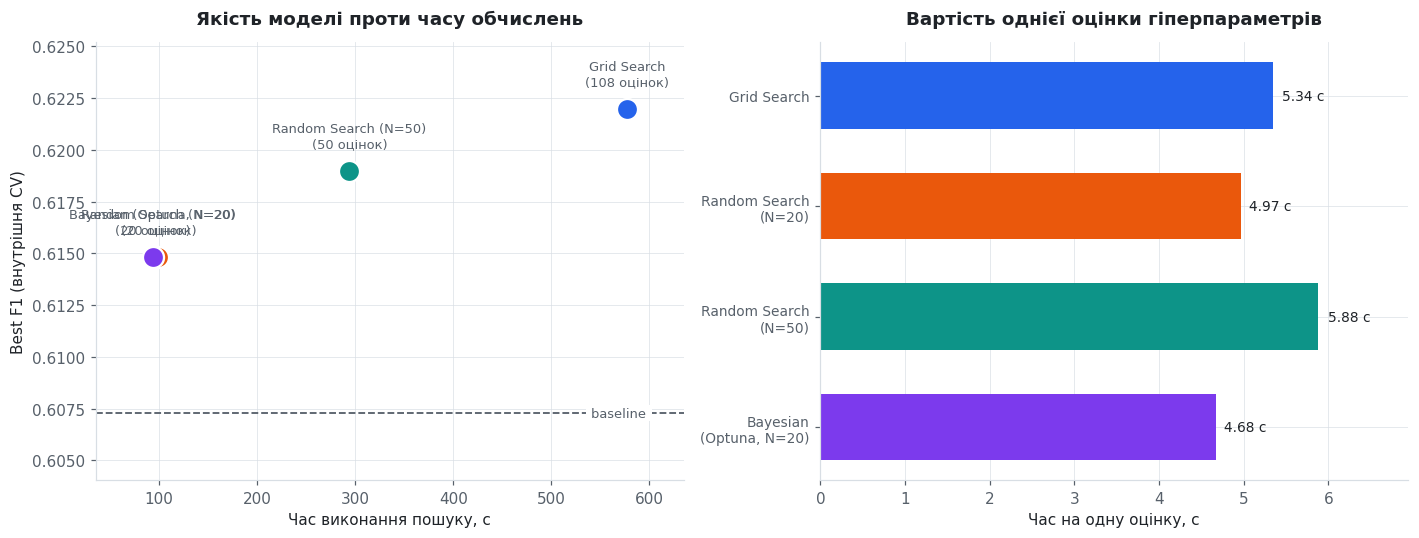

Ліва панель: що правіше точка, то дорожчий метод; що вище – то кращий.
Права панель: вартість однієї оцінки майже однакова в усіх методів,
тож різниця в загальному часі пояснюється тільки кількістю оцінок.


In [17]:
# --- Графік залежності "Якість моделі / Час обчислень" (вимога методички) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Ліва панель: якість проти часу
ax = axes[0]
for name, r in SEARCH_RESULTS.items():
    ax.scatter(r["Час, с"], r["Best Score (Inner CV)"], s=190,
               color=method_color(name), zorder=3, edgecolor="white", linewidth=1.5)
    # Підпис із кількістю оцінок: пояснює, чому точка стоїть саме тут
    ax.annotate(f"{name}\n({r['Оцінок']} оцінок)",
                (r["Час, с"], r["Best Score (Inner CV)"]),
                textcoords="offset points", xytext=(0, 16),
                ha="center", fontsize=8.5, color=MUTED)

# Горизонтальна лінія baseline: усе, що над нею, – виграш від оптимізації
ax.axhline(BASELINE_F1, color=MUTED, linestyle="--", linewidth=1.2, zorder=1)
ax.text(ax.get_xlim()[1], BASELINE_F1, " baseline ", va="center",
        ha="right", fontsize=8.5, color=MUTED,
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
style_axes(ax, "Якість моделі проти часу обчислень",
           "Час виконання пошуку, с", "Best F1 (внутрішня CV)")
ax.margins(y=0.22, x=0.12)

# Права панель: час на одну оцінку – перевірка, що методи порівнювані.
# Якщо вартість однієї оцінки однакова, різниця в сумарному часі
# пояснюється виключно кількістю оцінок, а не "важчими" обчисленнями.
ax = axes[1]
names = list(SEARCH_RESULTS)
per_eval = [SEARCH_RESULTS[n]["Час, с"] / SEARCH_RESULTS[n]["Оцінок"] for n in names]
bars = ax.barh(range(len(names)), per_eval,
               color=[method_color(n) for n in names], height=0.6)
ax.set_yticks(range(len(names)))
ax.set_yticklabels([n.replace(" (", "\n(") for n in names], fontsize=9)
ax.invert_yaxis()
for b, v in zip(bars, per_eval):
    ax.text(b.get_width() * 1.02, b.get_y() + b.get_height() / 2,
            f"{v:.2f} с", va="center", fontsize=9, color=INK)
style_axes(ax, "Вартість однієї оцінки гіперпараметрів",
           "Час на одну оцінку, с", "")
ax.margins(x=0.18)

plt.tight_layout()
plt.show()

print("Ліва панель: що правіше точка, то дорожчий метод; що вище – то кращий.")
print("Права панель: вартість однієї оцінки майже однакова в усіх методів,")
print("тож різниця в загальному часі пояснюється тільки кількістю оцінок.")


### Комірка 2.7 – динаміка збіжності пошуку

Графік показує, як зростає найкраще знайдене значення метрики з кожною новою
оцінкою. Він відповідає на питання, якого немає в підсумковій таблиці: **коли**
саме метод знайшов свій результат.

Якщо крива виходить на плато після десятка оцінок, решта бюджету витрачена
даремно – і це прямий аргумент на користь ранньої зупинки в реальних задачах.
Різниця між випадковим і байєсівським пошуком має бути помітна саме на початку:
другий після кількох випробувань починає обирати точки не навмання.

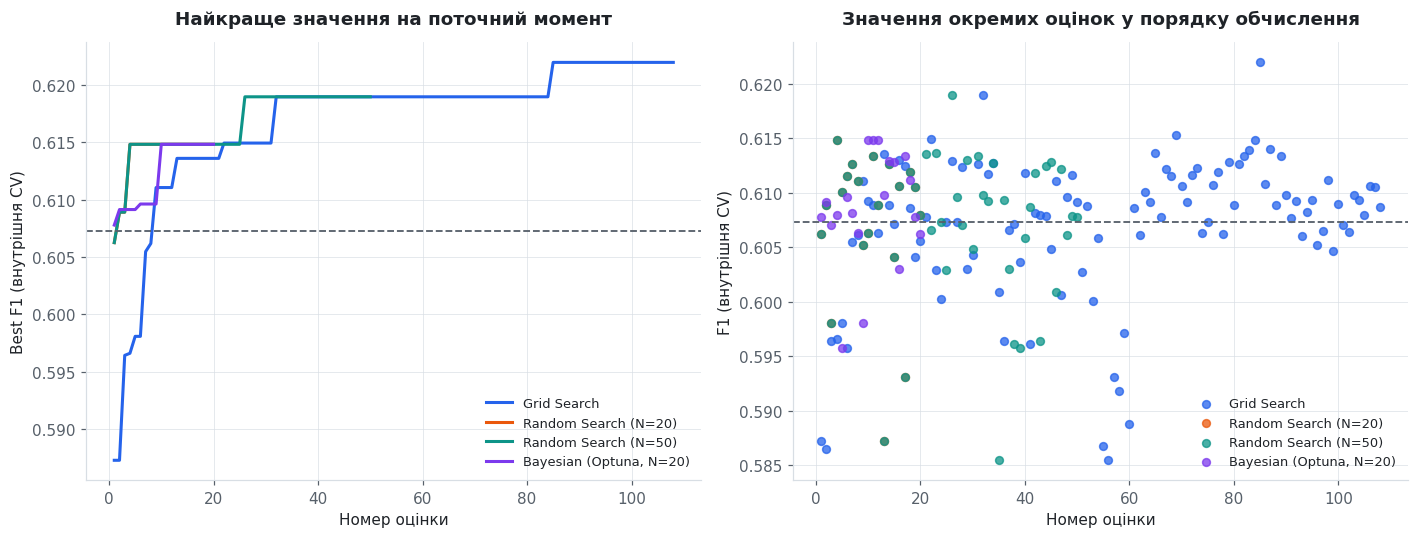

Скільки оцінок знадобилося, щоб досягти 99 % власного найкращого результату:
  Grid Search                 32 з 108 (30 % бюджету)
  Random Search (N=20)         2 з  20 (10 % бюджету)
  Random Search (N=50)         4 з  50 (8 % бюджету)
  Bayesian (Optuna, N=20)      2 з  20 (10 % бюджету)


In [18]:
# --- Динаміка збіжності методів пошуку ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Ліва панель: найкраще на поточний момент (монотонно неспадна крива).
# Плато означає, що решта бюджету пошуку витрачена даремно.
ax = axes[0]
for name, r in SEARCH_RESULTS.items():
    ax.plot(np.arange(1, len(r["Збіжність"]) + 1), r["Збіжність"],
            label=name, color=method_color(name), linewidth=2)
ax.axhline(BASELINE_F1, color=MUTED, linestyle="--", linewidth=1.2)
style_axes(ax, "Найкраще значення на поточний момент",
           "Номер оцінки", "Best F1 (внутрішня CV)")
ax.legend(fontsize=8.5, loc="lower right")

# Права панель: значення КОЖНОЇ оцінки без накопичення максимуму.
# Тут видно саму стратегію: випадковий пошук розкидає точки рівномірно,
# байєсівський після кількох спроб тримається верхньої частини графіка.
ax = axes[1]
for name, r in SEARCH_RESULTS.items():
    ax.scatter(np.arange(1, len(r["Історія"]) + 1), r["Історія"],
               label=name, color=method_color(name), s=26, alpha=0.75)
ax.axhline(BASELINE_F1, color=MUTED, linestyle="--", linewidth=1.2)
style_axes(ax, "Значення окремих оцінок у порядку обчислення",
           "Номер оцінки", "F1 (внутрішня CV)")
ax.legend(fontsize=8.5, loc="lower right")

plt.tight_layout()
plt.show()

# Скільки оцінок знадобилося кожному методу, щоб дійти до 99 % свого результату.
# Це практична міра "коли можна було зупинитися".
print("Скільки оцінок знадобилося, щоб досягти 99 % власного найкращого результату:")
for name, r in SEARCH_RESULTS.items():
    target = r["Best Score (Inner CV)"] * 0.99
    # argmax по булевому масиву дає індекс ПЕРШОГО значення True
    reached = int(np.argmax(r["Збіжність"] >= target)) + 1
    print(f"  {name:<26} {reached:3d} з {r['Оцінок']:3d} "
          f"({reached / r['Оцінок'] * 100:.0f} % бюджету)")


### Комірка 2.8 – що саме впливає на якість: аналіз простору

Повний перебір дав метрику для всіх 54 комбінацій, тож ми маємо повну карту
простору. Це дозволяє відповісти на питання, яке зазвичай лишається без відповіді:
**чи всі чотири гіперпараметри справді важливі?**

Для кожного параметра показано розподіл F1 за його значеннями. Якщо розподіли
накладаються один на одного, параметр майже не впливає, і його можна було б
зафіксувати, скоротивши простір. Саме ця властивість реальних задач пояснює, чому
випадковий пошук такий ефективний: він не витрачає бюджет на перебір комбінацій
неважливих параметрів.

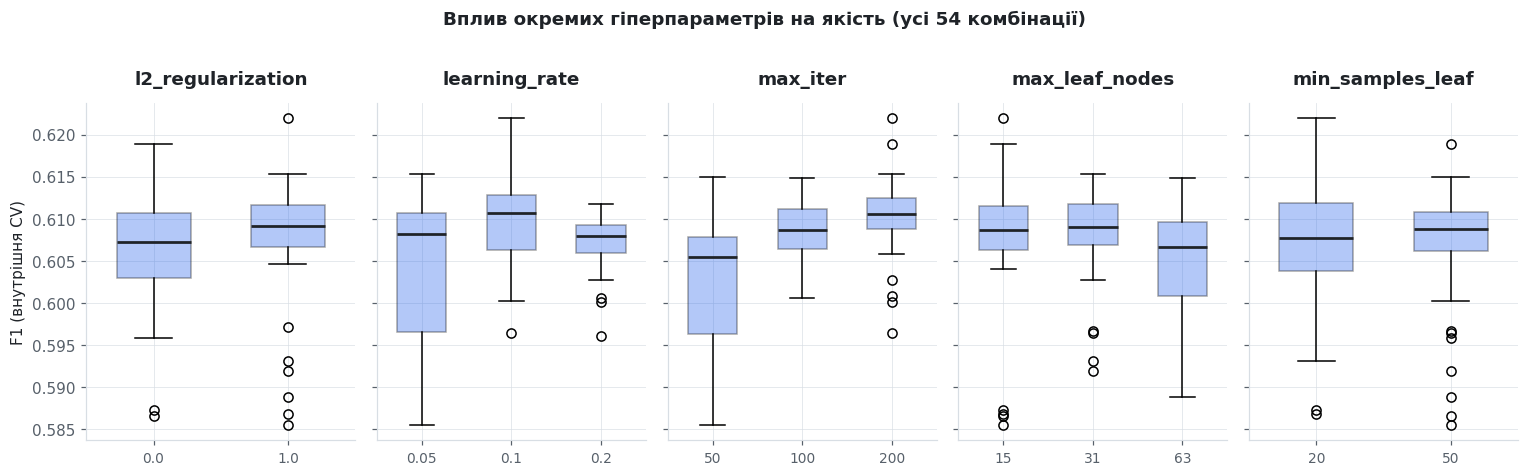

,Гіперпараметр,Розмах медіан F1,Найкраще значення
2,max_iter,0.0052,200.0
1,learning_rate,0.0027,0.1
3,max_leaf_nodes,0.0024,31.0
0,l2_regularization,0.0020,1.0
4,min_samples_leaf,0.0011,50.0


Що більший розмах медіан, то сильніше параметр впливає на результат.
Найвпливовіший параметр: max_iter (розмах 0.0052)
Найменш впливовий:       min_samples_leaf (розмах 0.0011)

Параметри з малим розмахом можна фіксувати: їх перебір витрачає бюджет,
майже не змінюючи результат. Саме на цьому й виграє випадковий пошук.


In [19]:
# --- Вплив окремих гіперпараметрів (за результатами повного перебору) ---
# cv_results_ повного перебору містить рядок на КОЖНУ комбінацію простору,
# тож це повна карта залежності "гіперпараметри -> якість".
grid_res = pd.DataFrame(grid_search.cv_results_)
param_cols = [c for c in grid_res.columns if c.startswith("param_")]

fig, axes = plt.subplots(1, len(param_cols), figsize=(14, 4.2), sharey=True)

influence = []
for ax, col in zip(axes, param_cols):
    short = col.replace("param_model__", "")
    values = sorted(grid_res[col].unique())
    # Групуємо F1 за кожним значенням параметра
    groups = [grid_res.loc[grid_res[col] == v, "mean_test_f1"].values for v in values]

    # Діаграма розмаху: кожен "ящик" – розподіл F1 по всіх комбінаціях,
    # у яких цей параметр мав дане значення, за будь-яких значень решти.
    bp = ax.boxplot(groups, tick_labels=[str(v) for v in values],
                    patch_artist=True, widths=0.55)
    for patch in bp["boxes"]:
        patch.set_facecolor(PALETTE[0]); patch.set_alpha(0.35)
    for med in bp["medians"]:
        med.set_color(INK); med.set_linewidth(1.8)

    # Розмах медіан – проста міра впливу параметра
    medians = [np.median(g) for g in groups]
    influence.append({"Гіперпараметр": short,
                      "Розмах медіан F1": max(medians) - min(medians),
                      "Найкраще значення": values[int(np.argmax(medians))]})
    style_axes(ax, short, "", "F1 (внутрішня CV)" if col == param_cols[0] else "")
    ax.tick_params(axis="x", labelsize=9)

plt.suptitle("Вплив окремих гіперпараметрів на якість (усі 54 комбінації)",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

influence = pd.DataFrame(influence).sort_values("Розмах медіан F1", ascending=False)
influence["Розмах медіан F1"] = influence["Розмах медіан F1"].round(4)
display(influence)

print("Що більший розмах медіан, то сильніше параметр впливає на результат.")
print(f"Найвпливовіший параметр: {influence.iloc[0]['Гіперпараметр']} "
      f"(розмах {influence.iloc[0]['Розмах медіан F1']:.4f})")
print(f"Найменш впливовий:       {influence.iloc[-1]['Гіперпараметр']} "
      f"(розмах {influence.iloc[-1]['Розмах медіан F1']:.4f})")
print("\nПараметри з малим розмахом можна фіксувати: їх перебір витрачає бюджет,")
print("майже не змінюючи результат. Саме на цьому й виграє випадковий пошук.")


---
# Розділ 3. Дослідження 2: оцінка впливу витоку даних

**Етап 3 методички:** побудувати два експериментальних пайплайни – некоректний
(з витоком) і коректний (без витоку); порівняти отримані валідаційні метрики та
оцінити величину штучного завищення якості.

**Що таке витік даних.** Витік виникає, коли в навчанні бере участь інформація,
якої на момент прогнозу не існувало б. У контексті крос-валідації це означає
просту річ: будь-яка величина, обчислена на **всій** вибірці до поділу на фолди,
містить сліди тих рядків, на яких модель потім перевіряється.

**Чому це не дрібниця.** Витік не псує модель – він псує **оцінку** моделі. Числа
в таблиці стають кращими, модель лишається тією самою. Помилку неможливо помітити
з самого звіту: вона виявляється вже після впровадження, коли реальна якість
виявляється нижчою за обіцяну.

**Джерела витоку в нашому конвеєрі.** Їх два, різної природи:

1. **Статистики ознак.** Параметри IterativeImputer, коефіцієнти Yeo-Johnson,
   частоти категорій – усе це обчислюється з даних. Навчені на всій вибірці, вони
   переносять у навчальні рядки інформацію про перевірочні.
2. **Цільове кодування.** Target Encoding замінює категорію середнім значенням
   **цільової змінної**. Без крос-фітингу код рядка містить його власну мітку –
   модель фактично отримує частину відповіді серед ознак.

Розділ вимірює внесок кожного джерела, а головне – з'ясовує, **від чого залежить
величина витоку**. Відповідь на це питання виявилася змістовнішою за саме
порівняння двох пайплайнів.

### Комірка 3.1 – два експериментальних пайплайни

Різниця між пайплайнами – виключно в **моменті навчання обробки**, модель і фолди
в обох випадках однакові.

**Коректний пайплайн.** Обробка й модель об'єднані в `Pipeline`. Коли
`cross_validate` розбиває дані на фолди, він викликає `fit` усього пайплайна лише
на навчальній частині фолда. Перевірочні рядки обробляються вже навченими
перетворювачами – рівно так, як поводитимуться майбутні дані.

**Некоректний пайплайн.** Обробка застосовується до всієї вибірки одразу, а
крос-валідація запускається вже на готовій матриці. Так виглядає найпоширеніша
помилка в навчальних прикладах: спочатку «підготуємо дані», потім «перевіримо
модель».

Обидві функції приймають однакові параметри й повертають однаковий набір метрик,
щоб результати можна було порівнювати напряму.

In [20]:
# --- Два експериментальних пайплайни (Етап 3 методички) ---
# Для чистоти експерименту фіксуємо гіперпараметри моделі: різниця в метриках
# має пояснюватися ТІЛЬКИ протоколом обробки, а не налаштуванням моделі.
LEAK_MODEL_PARAMS = dict(learning_rate=0.1, max_iter=200, max_leaf_nodes=31,
                         min_samples_leaf=20)

def eval_correct(oof_target=True, te_keys=("Location",)):
    """КОРЕКТНО: обробка навчається всередині кожного фолда.

    Pipeline гарантує, що prep.fit_transform бачить лише навчальну частину
    фолда, а перевірочна проходить через prep.transform.
    """
    pipe = Pipeline([("prep", WeatherPreprocessor(oof_target=oof_target,
                                                  te_keys=te_keys)),
                     ("model", make_model(**LEAK_MODEL_PARAMS))],
                    memory=PREP_CACHE)
    return cross_validate(pipe, X_opt, y_opt, scoring=SCORERS,
                          cv=INNER_CV, n_jobs=1)

def eval_leaky(oof_target=True, te_keys=("Location",)):
    """НЕКОРЕКТНО: обробка навчається на ВСІХ рядках до поділу на фолди.

    Матриця готується один раз, і крос-валідація вже не може "не знати"
    про перевірочні рядки: їхні значення вплинули на кожен перетворювач.
    """
    prep = WeatherPreprocessor(oof_target=oof_target, te_keys=te_keys)
    Z_all = prep.fit_transform(X_opt, y_opt)       # <- витік саме тут
    return cross_validate(make_model(**LEAK_MODEL_PARAMS), Z_all, y_opt,
                          scoring=SCORERS, cv=INNER_CV, n_jobs=1)

def metrics_of(cv_out):
    """Зводить результат cross_validate до трьох середніх значень метрик.

    Беремо саме test_*, а не train_*: нас цікавить оцінка на перевірочних
    фолдах – та сама, яку в реальній роботі вписали б у звіт.
    """
    return {"F1": cv_out["test_f1"].mean(),
            "ROC-AUC": cv_out["test_roc_auc"].mean(),
            "PR-AUC": cv_out["test_pr_auc"].mean()}

print("Два пайплайни визначено.")
print(f"Модель в обох однакова: {LEAK_MODEL_PARAMS}")
print(f"Фолди в обох однакові:  {INNER_CV.get_n_splits()} стратифіковані")
print("\nЄдина відмінність – момент навчання перетворювачів даних.")


Два пайплайни визначено.
Модель в обох однакова: {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}
Фолди в обох однакові:  3 стратифіковані

Єдина відмінність – момент навчання перетворювачів даних.


### Комірка 3.2 – порівняння двох пайплайнів на конвеєрі ЛР №1

Запускаємо обидва протоколи на тому самому конвеєрі, що використовувався в
розділах 1–2. Некоректний варіант беремо в найповнішому вигляді: обробка навчена
на всій вибірці **і** цільове кодування без крос-фітингу – тобто обидва джерела
витоку одночасно. Саме так виглядає типовий результат «швидкого» експерименту.

Величина різниці і є **штучним завищенням якості**, якого вимагає методичка.

In [21]:
# --- Оцінка обох пайплайнів (вимога методички: порівняти метрики) ---
t0 = time.time()
cv_correct = eval_correct(oof_target=True)    # все правильно
cv_leaky   = eval_leaky(oof_target=False)     # обидва джерела витоку
t_leak_exp = time.time() - t0

# Модель, фолди, дані й гіперпараметри в обох випадках ідентичні,
# тому вся різниця в метриках – наслідок виключно протоколу обробки.
m_correct, m_leaky = metrics_of(cv_correct), metrics_of(cv_leaky)

leak_table = pd.DataFrame({
    "Метрика": list(m_correct),
    "Коректний пайплайн": [m_correct[k] for k in m_correct],
    "Некоректний пайплайн (з витоком)": [m_leaky[k] for k in m_correct],
})
# Абсолютне завищення – скільки "безкоштовних" пунктів метрики дає помилка
# протоколу; відносне – та сама величина у відсотках від чесного результату.
leak_table["Абсолютне завищення"] = (leak_table["Некоректний пайплайн (з витоком)"]
                                     - leak_table["Коректний пайплайн"])
leak_table["Відносне завищення, %"] = (leak_table["Абсолютне завищення"]
                                       / leak_table["Коректний пайплайн"] * 100)
display(leak_table.round(4))

f1_gain = m_leaky["F1"] - m_correct["F1"]
print(f"Експеримент виконано за {t_leak_exp:.1f} с")
print(f"\nF1 за коректного протоколу: {m_correct['F1']:.4f}")
print(f"F1 за протоколу з витоком:  {m_leaky['F1']:.4f}")
print(f"Штучне завищення F1:        {f1_gain:+.4f} "
      f"({f1_gain / m_correct['F1'] * 100:+.1f} %)")

# Скільки рядків припадає на одну категорію цільового кодування –
# ця величина знадобиться в наступній комірці.
n_loc = X_opt[HIGH_CARD_COL].nunique()
print(f"\nКатегорій у цільовому кодуванні: {n_loc} "
      f"({len(X_opt) / n_loc:.0f} рядків на категорію)")

# Розкид між фолдами – природна межа, нижче якої різниця нічого не означає
fold_spread = cv_correct["test_f1"].std()
print(f"Розкид F1 між фолдами коректного пайплайна: ±{fold_spread:.4f}")

if f1_gain > fold_spread:
    print("\nЗавищення перевищує розкид між фолдами, тобто є реальним ефектом.")
    print("Наступна комірка показує, від чого залежить його величина.")
else:
    print("\nЗавищення НЕ перевищує розкид між фолдами: на цьому конвеєрі помилка")
    print("протоколу себе майже не виявляє. Це не означає, що вона безпечна –")
    print("наступна комірка показує конвеєр, на якому та сама помилка коштує дорого.")


,Метрика,Коректний пайплайн,Некоректний пайплайн (з витоком),Абсолютне завищення,"Відносне завищення, %"
0,F1,0.6117,0.6055,-0.0062,-1.0125
1,ROC-AUC,0.8708,0.8711,0.0003,0.0361
2,PR-AUC,0.7029,0.7020,-0.0009,-0.1243


Експеримент виконано за 17.3 с

F1 за коректного протоколу: 0.6117
F1 за протоколу з витоком:  0.6055
Штучне завищення F1:        -0.0062 (-1.0 %)

Категорій у цільовому кодуванні: 49 (245 рядків на категорію)
Розкид F1 між фолдами коректного пайплайна: ±0.0151

Завищення НЕ перевищує розкид між фолдами: на цьому конвеєрі помилка
протоколу себе майже не виявляє. Це не означає, що вона безпечна –
наступна комірка показує конвеєр, на якому та сама помилка коштує дорого.


### Комірка 3.3 – від чого залежить величина витоку

Попередня комірка дала несподівано скромний результат – завищення виявилося
того самого порядку, що й випадковий розкид між фолдами. Це не свідчення того,
що витоком можна знехтувати. Це свідчення того, що **величина витоку не є
властивістю самої помилки**: вона залежить від того, скільки інформації про
мітку здатне просочитися через конкретне перетворення.

Оцінити це можна прямо. Цільове кодування замінює категорію середнім її міток.
Якщо в категорії *n* рядків, то власна мітка рядка становить приблизно частку
1 / (n + m) його коду, де *m* – параметр згладжування. Для 49 станцій на
12 000 рядків це близько 245 спостережень на станцію, тобто внесок власної
мітки – менш ніж піввідсотка. Просочуватися просто нічому.

Перевіряємо це, змінивши **одну** річ – ключ цільового кодування. Замість станції
беремо взаємодію «станція × місяць». Це цілком змістовна ознака: частота дощів у
Дарвіні в січні й у липні справді різна, і подібні ознаки створювалися в ЛР №1.
Але категорій стає більш ніж удесятеро більше, рядків у кожній – відповідно
менше, і той самий код починає нести помітну частку власної мітки рядка.

Усе інше – модель, фолди, дані, обидва протоколи – лишається без змін.

In [22]:
# --- Чи залежить величина витоку від кардинальності кодування ---
FINE_KEYS = ("Location", "LocMonth")      # станція + взаємодія станції з місяцем

t0 = time.time()
cv_correct_fine = eval_correct(oof_target=True,  te_keys=FINE_KEYS)
cv_leaky_fine   = eval_leaky(oof_target=False,   te_keys=FINE_KEYS)
t_fine = time.time() - t0

m_correct_fine, m_leaky_fine = metrics_of(cv_correct_fine), metrics_of(cv_leaky_fine)
f1_gain_fine = m_leaky_fine["F1"] - m_correct_fine["F1"]

# Скільки категорій і скільки рядків на категорію в кожному варіанті
n_fine = TE_KEYS["LocMonth"](X_opt).nunique()
cardinality = pd.DataFrame({
    "Ключ цільового кодування": ["Location", "Location × month"],
    "Категорій": [n_loc, n_fine],
    "Рядків на категорію": [round(len(X_opt) / n_loc), round(len(X_opt) / n_fine)],
    # Частка власної мітки в коді рядка: 1 / (n + m), де m – згладжування
    "Частка власної мітки в коді, %": [
        round(100 / (len(X_opt) / n_loc + 20), 2),
        round(100 / (len(X_opt) / n_fine + 20), 2)],
    "F1 коректно": [round(m_correct["F1"], 4), round(m_correct_fine["F1"], 4)],
    "F1 з витоком": [round(m_leaky["F1"], 4), round(m_leaky_fine["F1"], 4)],
    "Завищення F1": [round(f1_gain, 4), round(f1_gain_fine, 4)],
})
display(cardinality)

honest_gain = m_correct_fine["F1"] - m_correct["F1"]     # що ознака дає насправді
apparent_gain = m_leaky_fine["F1"] - m_correct["F1"]     # що вона "дає" з витоком

print(f"Експеримент виконано за {t_fine:.1f} с\n")
print(f"Кардинальність: {n_loc} -> {n_fine} категорій")
print(f"Рядків на категорію: {len(X_opt) / n_loc:.0f} -> {len(X_opt) / n_fine:.0f}")
print(f"Завищення F1: {f1_gain:+.4f} (Location) -> "
      f"{f1_gain_fine:+.4f} (Location × month)")
# Відношення має сенс лише тоді, коли базове завищення само по собі помітне
if f1_gain > fold_spread:
    print(f"Співвідношення: {f1_gain_fine / f1_gain:.0f} : 1")
else:
    print("На базовому конвеєрі завищення не відрізнялося від нуля, тому важливе")
    print("не відношення, а сам перехід від «ефекту немає» до «ефект є».")
print(f"\nТа сама ознака, два протоколи:")
print(f"  за коректного протоколу вона дала  {honest_gain:+.4f}")
print(f"  за некоректного – нібито           {apparent_gain:+.4f}")
print(f"  різниця                            {apparent_gain - honest_gain:+.4f}")
print("\nЦя різниця і є витоком: інформація, якої в ознаці насправді немає.")
print("Помилка протоколу не змінилася – змінилося лише те, скільки інформації")
print("про мітку здатне крізь неї просочитися.")


,Ключ цільового кодування,Категорій,Рядків на категорію,"Частка власної мітки в коді, %",F1 коректно,F1 з витоком,Завищення F1
0,Location,49,245,0.38,0.6117,0.6055,-0.0062
1,Location × month,588,20,2.47,0.6123,0.6272,0.0149


Експеримент виконано за 20.0 с

Кардинальність: 49 -> 588 категорій
Рядків на категорію: 245 -> 20
Завищення F1: -0.0062 (Location) -> +0.0149 (Location × month)
На базовому конвеєрі завищення не відрізнялося від нуля, тому важливе
не відношення, а сам перехід від «ефекту немає» до «ефект є».

Та сама ознака, два протоколи:
  за коректного протоколу вона дала  +0.0006
  за некоректного – нібито           +0.0155
  різниця                            +0.0149

Ця різниця і є витоком: інформація, якої в ознаці насправді немає.
Помилка протоколу не змінилася – змінилося лише те, скільки інформації
про мітку здатне крізь неї просочитися.


### Комірка 3.4 – внесок окремих джерел витоку

Тепер розділяємо сумарний ефект на складові: скільки дає навчання обробки до
поділу, а скільки – цільове кодування без крос-фітингу. Чотири конфігурації
відрізняються лише двома перемикачами.

| № | Обробка навчається | Цільове кодування | Що показує |
|---|---|---|---|
| 1 | у кожному фолді | out-of-fold | коректна оцінка |
| 2 | у кожному фолді | без крос-фітингу | внесок цільового кодування |
| 3 | на всіх рядках | out-of-fold | внесок статистик ознак |
| 4 | на всіх рядках | без крос-фітингу | обидва джерела разом |

Розклад робимо на конвеєрі з кодуванням високої кардинальності: на базовому
конвеєрі всі чотири значення відрізнялися б у четвертому знаку, і порівнювати
було б нічого.

Результат цього розкладу виявився найнесподіванішим у всій роботі, тож варто
заздалегідь пояснити, на що саме дивитися. Інтуїція підказує, що кожне джерело
витоку окремо має трохи завищувати оцінку, а разом вони дадуть суму. Числа
нижче показують інше – і причина цього пояснена одразу після таблиці.

In [23]:
# --- Внесок окремих джерел витоку ---
# Кожна конфігурація відрізняється від коректної рівно одним перемикачем,
# тому різницю метрик можна приписати саме цьому джерелу витоку.
configs = [
    ("1. Коректний протокол",            eval_correct, True,  "у фолді", "out-of-fold"),
    ("2. Витік через цільове кодування", eval_correct, False, "у фолді", "без крос-фітингу"),
    ("3. Витік через статистики ознак",  eval_leaky,   True,  "на всіх", "out-of-fold"),
    ("4. Обидва джерела разом",          eval_leaky,   False, "на всіх", "без крос-фітингу"),
]

rows = []
t0 = time.time()
for label, fn, oof, where, te_mode in configs:
    m = metrics_of(fn(oof_target=oof, te_keys=FINE_KEYS))
    rows.append({"Конфігурація": label,
                 "Обробка навчається": where,
                 "Цільове кодування": te_mode,
                 **{k: round(v, 4) for k, v in m.items()}})
    print(f"  {label:<36} F1 = {m['F1']:.4f}")
t_sources = time.time() - t0

sources = pd.DataFrame(rows)
# Завищення рахуємо відносно першої, коректної конфігурації
base_f1 = sources.loc[0, "F1"]
sources["Завищення F1"] = (sources["F1"] - base_f1).round(4)
display(sources)

d_te, d_stat, d_both = (sources.loc[i, "Завищення F1"] for i in (1, 2, 3))

print(f"\nОбчислено за {t_sources:.1f} с")
print(f"Внесок цільового кодування:  {d_te:+.4f}")
print(f"Внесок статистик ознак:      {d_stat:+.4f}")
print(f"Обидва разом:                {d_both:+.4f}")

# Ефекти НЕ адитивні: сума окремих внесків не дорівнює спільному.
print(f"\nСума окремих внесків:     {d_te + d_stat:+.4f}")
print(f"Фактичний спільний ефект: {d_both:+.4f}")

print("\n--- Чому так ---")
print("Вирішує не наявність витоку, а те, чи досягає він ПЕРЕВІРОЧНИХ рядків.\n")
if d_te < 0:
    print("Конфігурація 2: кодувальник навчається всередині фолда, тому власну мітку")
    print("отримують лише навчальні рядки. Перевірочні потрапляють у категорії, яких")
    print("у цьому фолді не було, і дістають глобальне середнє. Модель довіряє ознаці,")
    print("яка на перевірці порожня, – і якість ПАДАЄ, а не зростає.")
else:
    print("Конфігурація 2: витік через цільове кодування дістався й перевірочних")
    print("рядків, тому оцінка завищена.")
print("\nКонфігурація 3: на всіх рядках навчено лише статистики ОЗНАК, не міток.")
print("Вони переносять властивості розподілів, а не відповіді, тому ефект малий.")
print("\nКонфігурація 4: кодувальник навчено на всіх рядках, тож власну мітку")
print("отримує КОЖЕН рядок, зокрема перевірочний. Саме це й завищує оцінку.")
print("\nЗвідси головний висновок розділу: завищує оцінку лише СИМЕТРИЧНИЙ витік –")
print("той, що однаково досягає обох частин фолда. Несиметричний витік не завищує")
print("оцінку, а псує саму модель, і помітити його за метриками ще важче.")


  1. Коректний протокол                F1 = 0.6123
  2. Витік через цільове кодування     F1 = 0.5960
  3. Витік через статистики ознак      F1 = 0.6178
  4. Обидва джерела разом              F1 = 0.6272


,Конфігурація,Обробка навчається,Цільове кодування,F1,ROC-AUC,PR-AUC,Завищення F1
0,1. Коректний протокол,у фолді,out-of-fold,0.6123,0.8693,0.6990,0.0000
1,2. Витік через цільове кодування,у фолді,без крос-фітингу,0.5960,0.8515,0.6770,-0.0163
2,3. Витік через статистики ознак,на всіх,out-of-fold,0.6178,0.8741,0.7135,0.0055
3,4. Обидва джерела разом,на всіх,без крос-фітингу,0.6272,0.8796,0.7202,0.0149



Обчислено за 36.0 с
Внесок цільового кодування:  -0.0163
Внесок статистик ознак:      +0.0055
Обидва разом:                +0.0149

Сума окремих внесків:     -0.0108
Фактичний спільний ефект: +0.0149

--- Чому так ---
Вирішує не наявність витоку, а те, чи досягає він ПЕРЕВІРОЧНИХ рядків.

Конфігурація 2: кодувальник навчається всередині фолда, тому власну мітку
отримують лише навчальні рядки. Перевірочні потрапляють у категорії, яких
у цьому фолді не було, і дістають глобальне середнє. Модель довіряє ознаці,
яка на перевірці порожня, – і якість ПАДАЄ, а не зростає.

Конфігурація 3: на всіх рядках навчено лише статистики ОЗНАК, не міток.
Вони переносять властивості розподілів, а не відповіді, тому ефект малий.

Конфігурація 4: кодувальник навчено на всіх рядках, тож власну мітку
отримує КОЖЕН рядок, зокрема перевірочний. Саме це й завищує оцінку.

Звідси головний висновок розділу: завищує оцінку лише СИМЕТРИЧНИЙ витік –
той, що однаково досягає обох частин фолда. Несиметричний витік не

### Комірка 3.5 – графік різниці метрик

Третій обов'язковий рисунок звіту: таблиця-графік різниці метрик для коректного та
некоректного препроцесингу.

Ліва панель порівнює три метрики в обох протоколах на обох конвеєрах, права –
розкладає завищення за джерелами. Разом вони відповідають на три питання:
наскільки завищена оцінка, від чого залежить величина завищення і звідки воно
береться.

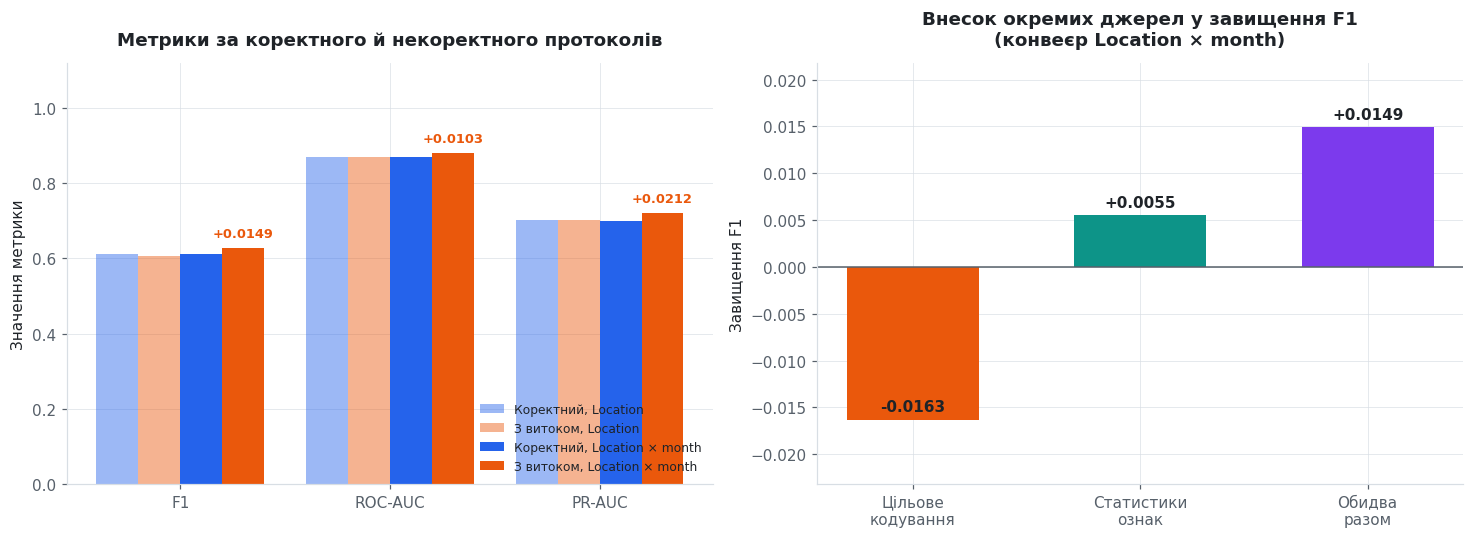

Ліва панель: світлі стовпці – базовий конвеєр, насичені – з кодуванням
високої кардинальності. Та сама помилка протоколу коштує по-різному.
Права панель: стовпці зі знаком. Додатний – оцінка завищена, від'ємний –
витік не завищив оцінку, а зіпсував модель (пояснення в комірці 3.4).


In [24]:
# --- Графік різниці метрик: коректний проти некоректного препроцесингу ---
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# Ліва панель: три метрики, два протоколи, два конвеєри
ax = axes[0]
metrics = list(m_correct)
x = np.arange(len(metrics))
w = 0.2
sets = [("Коректний, Location", m_correct, PALETTE[0], 0.45),
        ("З витоком, Location", m_leaky, PALETTE[1], 0.45),
        ("Коректний, Location × month", m_correct_fine, PALETTE[0], 1.0),
        ("З витоком, Location × month", m_leaky_fine, PALETTE[1], 1.0)]
for i, (label, mm, color, alpha) in enumerate(sets):
    ax.bar(x + (i - 1.5) * w, [mm[k] for k in metrics], w,
           label=label, color=color, alpha=alpha)
# Підпис величини завищення над кожною парою стовпців:
# саме це число і є відповіддю на вимогу методички "оцінити завищення".
for xi, k in zip(x, metrics):
    ax.annotate(f"{m_leaky_fine[k] - m_correct_fine[k]:+.4f}",
                (xi + 1.5 * w, max(m_leaky_fine[k], m_correct_fine[k]) + 0.03),
                ha="center", fontsize=8.5, color=PALETTE[1], fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.12)
ax.legend(fontsize=8, loc="lower right")
style_axes(ax, "Метрики за коректного й некоректного протоколів", "", "Значення метрики")

# Права панель: розклад завищення F1 за джерелами
ax = axes[1]
labels = ["Цільове\nкодування", "Статистики\nознак", "Обидва\nразом"]
vals = [sources.loc[1, "Завищення F1"], sources.loc[2, "Завищення F1"],
        sources.loc[3, "Завищення F1"]]
bars = ax.bar(labels, vals, color=[PALETTE[1], PALETTE[2], PALETTE[3]], width=0.58)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2,
            v + (max(vals) - min(min(vals), 0)) * 0.03,
            f"{v:+.4f}", ha="center", fontsize=10, color=INK, fontweight="bold")
ax.axhline(0, color=MUTED, linewidth=1)
style_axes(ax, "Внесок окремих джерел у завищення F1\n(конвеєр Location × month)",
           "", "Завищення F1")
ax.margins(y=0.22)

plt.tight_layout()
plt.show()

print("Ліва панель: світлі стовпці – базовий конвеєр, насичені – з кодуванням")
print("високої кардинальності. Та сама помилка протоколу коштує по-різному.")
print("Права панель: стовпці зі знаком. Додатний – оцінка завищена, від'ємний –")
print("витік не завищив оцінку, а зіпсував модель (пояснення в комірці 3.4).")


### Комірка 3.6 – наслідок витоку для підбору гіперпараметрів

Попередні комірки показали, що витік завищує оцінку. Залишається важливіше
питання: чи змінює він **рішення**, які приймаються на основі цієї оцінки?

Експеримент: запускаємо випадковий пошук двічі – на некоректній матриці та в
коректному пайплайні. Потім обидві знайдені конфігурації навчаємо **чесно** й
перевіряємо на валідаційній вибірці 2016 року, якої не торкався жоден із пошуків.

Можливі результати різні за наслідками:

* якщо обрані гіперпараметри збігаються, витік зіпсував лише звіт;
* якщо вони різні й «витічна» конфігурація програє на 2016 році, витік зіпсував
  саме рішення – і наслідки вже не косметичні.

In [25]:
# --- Чи змінює витік вибір гіперпараметрів ---
# Пошук на НЕКОРЕКТНІЙ матриці: обробка вже застосована до всіх рядків,
# тому шукати доводиться тільки гіперпараметри моделі.
prep_leaky = WeatherPreprocessor(oof_target=False, te_keys=FINE_KEYS)
Z_leaky = prep_leaky.fit_transform(X_opt, y_opt)

# Простір той самий, але без префікса model__: тут шукаємо гіперпараметри
# голої моделі, а не пайплайна, бо обробку вже (помилково) застосовано.
grid_model_only = {k.replace("model__", ""): v for k, v in PARAM_GRID.items()}
rs_leaky = RandomizedSearchCV(make_model(), grid_model_only, n_iter=N_RND1,
                              scoring=SCORERS, refit=False, cv=INNER_CV,
                              n_jobs=1, random_state=RANDOM_STATE)
t0 = time.time()
rs_leaky.fit(Z_leaky, y_opt)
t_leaky_search = time.time() - t0

res_leaky = pd.DataFrame(rs_leaky.cv_results_)
i_leaky = res_leaky["mean_test_f1"].idxmax()
best_leaky = {f"model__{k}": v for k, v in res_leaky.loc[i_leaky, "params"].items()}
score_leaky = res_leaky.loc[i_leaky, "mean_test_f1"]

# Коректний пошук уже виконано в розділі 2 – беремо його результат
ref_name = f"Random Search (N={N_RND1})"
best_correct = SEARCH_RESULTS[ref_name]["Найкращі гіперпараметри"]
score_correct = SEARCH_RESULTS[ref_name]["Best Score (Inner CV)"]

def honest_valid_f1(params):
    """Чесна перевірка конфігурації: коректне навчання, незалежний 2016 рік.

    Хоч би як було знайдено гіперпараметри, перевіряємо їх однаково –
    через коректний пайплайн на даних, яких не бачив жоден пошук.
    """
    clean = {k.replace("model__", ""): v for k, v in params.items()}
    pipe = Pipeline([("prep", WeatherPreprocessor()), ("model", make_model(**clean))])
    pipe.fit(X_opt, y_opt)
    return f1_score(y_valid, pipe.predict(df_valid))

valid_leaky = honest_valid_f1(best_leaky)
valid_correct = honest_valid_f1(best_correct)

decision = pd.DataFrame({
    "Протокол пошуку": ["Коректний (Pipeline)", "Некоректний (з витоком)"],
    "Обіцяний F1 (внутрішня CV)": [round(score_correct, 4), round(score_leaky, 4)],
    "Фактичний F1 (валідація 2016)": [round(valid_correct, 4), round(valid_leaky, 4)],
    "Обрані гіперпараметри": [
        ", ".join(f"{k.replace('model__', '')}={v}" for k, v in sorted(best_correct.items())),
        ", ".join(f"{k.replace('model__', '')}={v}" for k, v in sorted(best_leaky.items())),
    ],
})
decision["Переоцінка"] = (decision["Обіцяний F1 (внутрішня CV)"]
                          - decision["Фактичний F1 (валідація 2016)"]).round(4)
display(decision)

same = (best_leaky == best_correct)
print(f"Пошук на некоректній матриці виконано за {t_leaky_search:.1f} с")
print(f"\nОбрані конфігурації {'ЗБІГАЮТЬСЯ' if same else 'РІЗНІ'}")
print(f"Переоцінка за коректного протоколу: {decision.loc[0, 'Переоцінка']:+.4f}")
print(f"Переоцінка за протоколу з витоком:  {decision.loc[1, 'Переоцінка']:+.4f}")
print(f"\nРізниця фактичної якості двох конфігурацій на 2016 році: "
      f"{valid_leaky - valid_correct:+.4f}")
if same:
    print("\nВибір гіперпараметрів витік не змінив – обидва протоколи привели до")
    print("однієї конфігурації. Постраждала не модель, а ЗВІТ: обіцяне число")
    print(f"({score_leaky:.4f}) на реальних даних недосяжне ({valid_leaky:.4f}).")
    print("Саме тому таку помилку майже неможливо виявити з самого звіту.")
else:
    print("\nВитік змінив не лише звіт, а й САМЕ РІШЕННЯ: протоколи привели до")
    print("різних конфігурацій – у виробництво пішла б інша модель.")
    if valid_leaky >= valid_correct:
        print(f"Цього разу «витічна» конфігурація виявилася навіть трохи кращою "
              f"({valid_leaky - valid_correct:+.4f}),")
        print("але це випадковість, а не заслуга протоколу: пошук на спотвореній")
        print("оцінці не має жодних підстав обирати краще. Головне лишається тим самим –")
        print(f"обіцяний F1 {score_leaky:.4f} на реальних даних недосяжний "
              f"({valid_leaky:.4f}).")
    else:
        print(f"Обрана за витоком конфігурація програла чесній на {valid_correct - valid_leaky:.4f}")
        print("на даних 2016 року. Тут наслідки вже не косметичні.")


,Протокол пошуку,Обіцяний F1 (внутрішня CV),Фактичний F1 (валідація 2016),Обрані гіперпараметри,Переоцінка
0,Коректний (Pipeline),0.6148,0.6112,"l2_regularization=1.0, learning_rate=0.1, max_...",0.0036
1,Некоректний (з витоком),0.6385,0.6186,"l2_regularization=1.0, learning_rate=0.05, max...",0.0199


Пошук на некоректній матриці виконано за 88.1 с

Обрані конфігурації РІЗНІ
Переоцінка за коректного протоколу: +0.0036
Переоцінка за протоколу з витоком:  +0.0199

Різниця фактичної якості двох конфігурацій на 2016 році: +0.0074

Витік змінив не лише звіт, а й САМЕ РІШЕННЯ: протоколи привели до
різних конфігурацій – у виробництво пішла б інша модель.
Цього разу «витічна» конфігурація виявилася навіть трохи кращою (+0.0074),
але це випадковість, а не заслуга протоколу: пошук на спотвореній
оцінці не має жодних підстав обирати краще. Головне лишається тим самим –
обіцяний F1 0.6385 на реальних даних недосяжний (0.6186).


---
# Розділ 4. Дослідження 3: оцінка незміщеної якості (Nested Cross-Validation)

**Етап 4 методички:** реалізувати схему вкладеної крос-валідації – зовнішня петля
K = 5 для оцінки узагальнювальної здатності, внутрішня K = 3 для підбору
гіперпараметрів; порівняти тестову оцінку з внутрішньої CV та незміщену оцінку
із зовнішньої CV.

**Навіщо потрібна ще одна петля.** Розділ 3 показав витік через дані. Є й другий,
набагато менш очевидний різновид – **витік через вибір**. Навіть у бездоганному
пайплайні число `best_score_` залишається зміщеним угору, і ось чому.

Пошук гіперпараметрів перебирає десятки конфігурацій і бере **максимум** їхніх
оцінок на одних і тих самих фолдах. Кожна оцінка містить випадкову похибку.
Максимум кількох десятків зашумлених величин систематично більший за максимум
їхніх істинних значень: перемагає не лише справді краща конфігурація, а й та,
якій випадково пощастило саме на цих фолдах. Що більший бюджет пошуку, то сильніше
зміщення – вибір із 54 кандидатів зміщений більше, ніж вибір із 20.

**Як це виправляє вкладена CV.** Зовнішня петля відкладає частину даних **до**
початку пошуку. Пошук відбувається у внутрішній петлі й зовнішнього фолда не
бачить узагалі. Оцінка на ньому не брала участі у виборі, тому вона незміщена.
Ціна – у K разів більше обчислень.

Важливо розуміти, що вкладена CV оцінює не конкретну модель, а **всю процедуру**:
«підготувати дані, перебрати таку-то сітку, взяти найкраще». Відповідь, яку вона
дає, – якої якості слід очікувати, якщо повторити цю процедуру на нових даних.

### Комірка 4.1 – схема вкладеної крос-валідації

Перш ніж запускати обчислення, зобразимо схему: вона пояснює, які саме рядки бере
участь у кожному кроці. Верхній рядок – зовнішній поділ на 5 фолдів; для одного з
них показано, як його навчальна частина ділиться ще на 3 внутрішні фолди.

Ключове на рисунку – те, що зовнішній перевірочний фолд (жовтогарячий) не
з'являється у внутрішній петлі жодного разу.

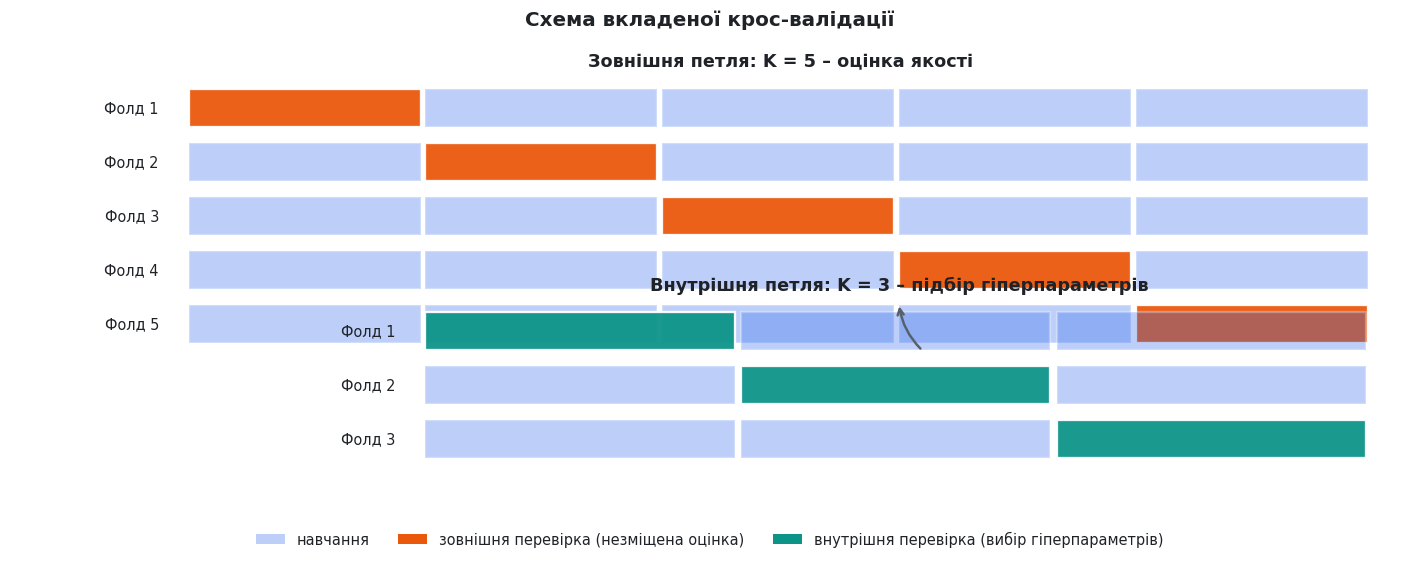

Зовнішніх фолдів: 5   внутрішніх: 3
Пошук повторюється 5 разів – по одному на кожен зовнішній фолд.
Жоден зовнішній перевірочний фолд не бере участі у виборі гіперпараметрів,
тому середнє за зовнішніми фолдами і є незміщеною оцінкою процедури.


In [26]:
# --- Схема вкладеної крос-валідації ---
fig, ax = plt.subplots(figsize=(13, 5.2))

# Схему малюємо прямокутниками: один прямокутник – один фолд даних.
K_OUT, K_IN = OUTER_CV.get_n_splits(), INNER_CV.get_n_splits()
W, H, GAP = 10.0, 0.52, 0.22      # ширина смуги, висота рядка, проміжок

# ----- Верхній блок: зовнішня петля -----
for k in range(K_OUT):
    yv = 4.6 - k * (H + GAP)
    for j in range(K_OUT):
        is_test = (j == k)
        ax.add_patch(plt.Rectangle((j * W / K_OUT, yv), W / K_OUT * 0.98, H,
                                   facecolor=PALETTE[1] if is_test else PALETTE[0],
                                   alpha=0.95 if is_test else 0.30,
                                   edgecolor="white", linewidth=1.5))
    ax.text(-0.25, yv + H / 2, f"Фолд {k + 1}", ha="right", va="center",
            fontsize=9.5, color=INK)

ax.text(W / 2, 4.6 + H + 0.30, f"Зовнішня петля: K = {K_OUT} – оцінка якості",
        ha="center", fontsize=11.5, fontweight="bold", color=INK)

# ----- Нижній блок: внутрішня петля для першого зовнішнього фолда -----
# Внутрішня петля вужча за зовнішню рівно на один фолд: зовнішній
# перевірочний фолд у підборі гіперпараметрів не бере участі взагалі.
inner_top = 1.55
inner_w = W * (K_OUT - 1) / K_OUT          # внутрішня петля працює без тест-фолда
for k in range(K_IN):
    yv = inner_top - k * (H + GAP)
    for j in range(K_IN):
        is_val = (j == k)
        ax.add_patch(plt.Rectangle((W / K_OUT + j * inner_w / K_IN, yv),
                                   inner_w / K_IN * 0.98, H,
                                   facecolor=PALETTE[2] if is_val else PALETTE[0],
                                   alpha=0.95 if is_val else 0.30,
                                   edgecolor="white", linewidth=1.5))
    ax.text(W / K_OUT - 0.25, yv + H / 2, f"Фолд {k + 1}", ha="right", va="center",
            fontsize=9.5, color=INK)

ax.text(W / K_OUT + inner_w / 2, inner_top + H + 0.30,
        f"Внутрішня петля: K = {K_IN} – підбір гіперпараметрів",
        ha="center", fontsize=11.5, fontweight="bold", color=INK)

# Стрілка від навчальної частини зовнішнього фолда до внутрішньої петлі
ax.annotate("", xy=(W / K_OUT + inner_w / 2, inner_top + H + 0.12),
            xytext=(W / 2 + 1.2, 4.6 - 4 * (H + GAP) - 0.10),
            arrowprops=dict(arrowstyle="->", color=MUTED, linewidth=1.6,
                            connectionstyle="arc3,rad=-0.18"))

# Легенда
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=PALETTE[0], alpha=0.30),
           plt.Rectangle((0, 0), 1, 1, facecolor=PALETTE[1]),
           plt.Rectangle((0, 0), 1, 1, facecolor=PALETTE[2])]
ax.legend(handles, ["навчання", "зовнішня перевірка (незміщена оцінка)",
                    "внутрішня перевірка (вибір гіперпараметрів)"],
          loc="lower center", ncol=3, fontsize=9.5, bbox_to_anchor=(0.5, -0.12))

ax.set_xlim(-1.5, W + 0.3); ax.set_ylim(-0.55, 5.9)
ax.axis("off"); ax.grid(False)
plt.title("Схема вкладеної крос-валідації", fontsize=13, fontweight="bold", pad=4)
plt.tight_layout()
plt.show()

print(f"Зовнішніх фолдів: {K_OUT}   внутрішніх: {K_IN}")
print(f"Пошук повторюється {K_OUT} разів – по одному на кожен зовнішній фолд.")
print("Жоден зовнішній перевірочний фолд не бере участі у виборі гіперпараметрів,")
print("тому середнє за зовнішніми фолдами і є незміщеною оцінкою процедури.")


### Комірка 4.2 – запуск вкладеної крос-валідації

Найдовша комірка ноутбука. Для кожної з чотирьох стратегій пошуку вкладена
крос-валідація виконується повністю: п'ять зовнішніх фолдів, у кожному – власний
пошук по внутрішніх трьох.

Для кожного зовнішнього фолда записуємо три речі:

* **внутрішню оцінку** – те число, яке пошук сам про себе повідомляє;
* **зовнішню оцінку** – якість обраної конфігурації на відкладеному фолді;
* **обрані гіперпараметри** – щоб перевірити, наскільки стабільний вибір.

Обчислення виконуються на меншій підвибірці, ніж у розділі 2: вкладена схема
вимагає у п'ять разів більше навчань при тому самому бюджеті. Порівняння
внутрішньої та зовнішньої оцінок від цього не страждає – обидві вимірюються на
тих самих даних.

In [27]:
# --- Вкладена крос-валідація для всіх чотирьох стратегій пошуку ---
def search_grid(Xtr, ytr):
    """Повний перебір у внутрішній петлі."""
    # scoring однією метрикою (не словником) – тоді стовпець у cv_results_
    # називається mean_test_score; кілька метрик тут зайві й лише сповільнили б.
    s = GridSearchCV(make_pipeline(), PARAM_GRID, scoring=SCORERS["f1"],
                     refit=False, cv=INNER_CV, n_jobs=1)
    s.fit(Xtr, ytr)
    r = pd.DataFrame(s.cv_results_)
    i = r["mean_test_score"].idxmax()
    return r.loc[i, "params"], r.loc[i, "mean_test_score"]

def make_search_random(n_iter):
    """Фабрика: випадковий пошук із заданим бюджетом."""
    def _search(Xtr, ytr):
        s = RandomizedSearchCV(make_pipeline(), PARAM_DIST, n_iter=n_iter,
                               scoring=SCORERS["f1"], refit=False, cv=INNER_CV,
                               n_jobs=1, random_state=RANDOM_STATE)
        s.fit(Xtr, ytr)
        r = pd.DataFrame(s.cv_results_)
        i = r["mean_test_score"].idxmax()
        return r.loc[i, "params"], r.loc[i, "mean_test_score"]
    return _search

def search_bayes(Xtr, ytr):
    """Байєсівська оптимізація у внутрішній петлі (нове дослідження щоразу)."""
    def obj(trial):
        p = {n: trial.suggest_categorical(n, v) for n, v in OPTUNA_SPACE}
        return cross_val_score(make_pipeline(**p), Xtr, ytr,
                               scoring=SCORERS["f1"], cv=INNER_CV, n_jobs=1).mean()
    # Для кожного зовнішнього фолда створюємо НОВЕ дослідження: історія
    # випробувань з інших фолдів не повинна впливати на цей пошук.
    st = optuna.create_study(direction="maximize",
                             sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    st.optimize(obj, n_trials=N_TRIALS_BAYES, show_progress_bar=False)
    return {f"model__{k}": v for k, v in st.best_params.items()}, st.best_value


def run_nested(name, search_fn):
    """Повна вкладена крос-валідація для однієї стратегії пошуку."""
    inner_scores, outer_scores, chosen = [], [], []
    t0 = time.time()
    # Зовнішня петля: кожен фолд по черзі стає відкладеною перевіркою
    for k, (tr, te) in enumerate(OUTER_CV.split(X_nst, y_nst), 1):
        X_tr, y_tr = X_nst.iloc[tr], y_nst[tr]
        X_te, y_te = X_nst.iloc[te], y_nst[te]

        # Пошук бачить ТІЛЬКИ навчальну частину зовнішнього фолда
        best_params, inner_best = search_fn(X_tr, y_tr)

        # Обрану конфігурацію навчаємо на всій навчальній частині
        # і перевіряємо на відкладеному фолді, який у пошуку не брав участі.
        clean = {kk.replace("model__", ""): vv for kk, vv in best_params.items()}
        model = make_pipeline(**clean).fit(X_tr, y_tr)
        outer = f1_score(y_te, model.predict(X_te))

        inner_scores.append(inner_best)
        outer_scores.append(outer)
        chosen.append(clean)
        print(f"    фолд {k}: внутрішня {inner_best:.4f}  зовнішня {outer:.4f}  "
              f"({', '.join(f'{a}={b}' for a, b in sorted(clean.items()))})")
    elapsed = time.time() - t0
    print(f"    -> {name}: незміщена оцінка {np.mean(outer_scores):.4f} "
          f"± {np.std(outer_scores):.4f}   за {elapsed / 60:.1f} хв\n")
    return {"Внутрішні": np.array(inner_scores), "Зовнішні": np.array(outer_scores),
            "Обрані": chosen, "Час, с": elapsed}


NESTED = {}
print(f"Вкладена крос-валідація на підвибірці {len(X_nst):,} рядків".replace(",", " "))
print(f"Зовнішніх фолдів {OUTER_CV.get_n_splits()}, внутрішніх {INNER_CV.get_n_splits()}")

# --- Прогрів кешу обробки ---
# Тут задіяні інші фолди, ніж у розділі 2, тож кеш для них порожній. Якби
# його наповнював перший же метод, він один оплатив би обробку для всіх
# решти, і порівняння часу між методами стало б несправедливим.
t0 = time.time()
for tr, _ in OUTER_CV.split(X_nst, y_nst):
    cross_val_score(make_pipeline(max_iter=50), X_nst.iloc[tr], y_nst[tr],
                    scoring=SCORERS["f1"], cv=INNER_CV, n_jobs=1)
print(f"Кеш обробки прогріто за {time.time() - t0:.0f} с "
      f"({OUTER_CV.get_n_splits() * INNER_CV.get_n_splits()} фолдів)\n")

t_nested_total = time.time()
for name, fn in [("Grid Search", search_grid),
                 (f"Random Search (N={N_RND1})", make_search_random(N_RND1)),
                 (f"Random Search (N={N_RND2})", make_search_random(N_RND2)),
                 (f"Bayesian (Optuna, N={N_TRIALS_BAYES})", search_bayes)]:
    print(f"  {name}:")
    NESTED[name] = run_nested(name, fn)

print(f"Усю вкладену крос-валідацію виконано за "
      f"{(time.time() - t_nested_total) / 60:.1f} хв")


Вкладена крос-валідація на підвибірці 3 000 рядків
Зовнішніх фолдів 5, внутрішніх 3
Кеш обробки прогріто за 15 с (15 фолдів)

  Grid Search:
    фолд 1: внутрішня 0.5893  зовнішня 0.6173  (l2_regularization=0.0, learning_rate=0.1, max_iter=50, max_leaf_nodes=31, min_samples_leaf=50)
    фолд 2: внутрішня 0.6199  зовнішня 0.5776  (l2_regularization=0.0, learning_rate=0.1, max_iter=100, max_leaf_nodes=15, min_samples_leaf=50)
    фолд 3: внутрішня 0.6333  зовнішня 0.5973  (l2_regularization=1.0, learning_rate=0.1, max_iter=50, max_leaf_nodes=15, min_samples_leaf=50)
    фолд 4: внутрішня 0.6045  зовнішня 0.6250  (l2_regularization=1.0, learning_rate=0.1, max_iter=50, max_leaf_nodes=31, min_samples_leaf=20)
    фолд 5: внутрішня 0.6231  зовнішня 0.6000  (l2_regularization=0.0, learning_rate=0.2, max_iter=100, max_leaf_nodes=15, min_samples_leaf=20)
    -> Grid Search: незміщена оцінка 0.6034 ± 0.0166   за 18.8 хв

  Random Search (N=20):
    фолд 1: внутрішня 0.5830  зовнішня 0.6290  (l2_

### Комірка 4.3 – внутрішня оцінка проти незміщеної

Головне порівняння етапу 4. Для кожної стратегії зіставляємо два числа, обчислені
**на тих самих даних**:

* **Best Score (Inner CV)** – середнє по п'яти зовнішніх фолдах тих значень, які
  пошук повідомляв про себе сам;
* **Unbiased Score (Nested CV)** – середнє по п'яти зовнішніх фолдах фактичної
  якості на відкладених даних.

Різниця між ними – **оптимістичне зміщення**: на стільки звичайна крос-валідація
переоцінює результат власного пошуку. Очікуємо, що зміщення зростатиме з бюджетом:
що більше конфігурацій перебрано, то більша ймовірність, що переможцю просто
пощастило на цих фолдах.

In [28]:
# --- Внутрішня оцінка проти незміщеної (головне порівняння етапу 4) ---
# Обидві оцінки обчислені на одній і тій самій підвибірці X_nst,
# тому їхня різниця – чиста міра зміщення, а не наслідок різних даних.
nested_tbl = pd.DataFrame([
    {"Метод оптимізації": name,
     "Оцінок": SEARCH_RESULTS[name]["Оцінок"],
     "Best Score (Inner CV)": r["Внутрішні"].mean(),
     "Unbiased Score (Nested CV)": r["Зовнішні"].mean(),
     "Зміщення": r["Внутрішні"].mean() - r["Зовнішні"].mean(),
     "Розкид зовнішніх фолдів (±)": r["Зовнішні"].std(),
     "Час вкладеної CV, хв": r["Час, с"] / 60}
    for name, r in NESTED.items()
]).round(4)
display(nested_tbl)

print("Обидві оцінки обчислені на одній підвибірці, тож порівняння пряме.\n")
for _, row in nested_tbl.iterrows():
    print(f"  {row['Метод оптимізації']:<26} "
          f"внутрішня {row['Best Score (Inner CV)']:.4f}  ->  "
          f"незміщена {row['Unbiased Score (Nested CV)']:.4f}   "
          f"зміщення {row['Зміщення']:+.4f}")

i_max = nested_tbl["Зміщення"].idxmax()
i_min = nested_tbl["Зміщення"].idxmin()
print(f"\nНайбільше зміщення: {nested_tbl.loc[i_max, 'Метод оптимізації']} "
      f"({nested_tbl.loc[i_max, 'Зміщення']:+.4f}, "
      f"{nested_tbl.loc[i_max, 'Оцінок']} оцінок)")
print(f"Найменше зміщення:  {nested_tbl.loc[i_min, 'Метод оптимізації']} "
      f"({nested_tbl.loc[i_min, 'Зміщення']:+.4f}, "
      f"{nested_tbl.loc[i_min, 'Оцінок']} оцінок)")

# Зв'язок між бюджетом пошуку і величиною зміщення.
# Теорія передбачає додатну кореляцію: максимум більшої кількості
# зашумлених оцінок систематично вищий за максимум істинних значень.
corr = np.corrcoef(nested_tbl["Оцінок"], nested_tbl["Зміщення"])[0, 1]
print(f"\nКореляція «бюджет пошуку – зміщення»: {corr:+.2f}")
print("Додатне значення підтверджує: що більше конфігурацій перебрано,")
print("то сильніше внутрішня оцінка переоцінює результат.")

# Переносимо незміщені оцінки в головну порівняльну таблицю розділу 2:
# саме там методичка вимагає бачити стовпець Unbiased Score.
for name, r in NESTED.items():
    comparison.loc[comparison["Метод оптимізації"] == name,
                   "Unbiased Score (Nested CV)"] = round(r["Зовнішні"].mean(), 4)
print("\nСтовпець Unbiased Score (Nested CV) у таблиці розділу 2 заповнено.")


,Метод оптимізації,Оцінок,Best Score (Inner CV),Unbiased Score (Nested CV),Зміщення,Розкид зовнішніх фолдів (±),"Час вкладеної CV, хв"
0,Grid Search,108,0.6140,0.6034,0.0106,0.0166,18.8345
1,Random Search (N=20),20,0.6095,0.6015,0.0080,0.0231,3.1620
2,Random Search (N=50),50,0.6102,0.5991,0.0110,0.0207,9.3051
3,"Bayesian (Optuna, N=20)",20,0.6115,0.6102,0.0013,0.0221,2.6317


Обидві оцінки обчислені на одній підвибірці, тож порівняння пряме.

  Grid Search                внутрішня 0.6140  ->  незміщена 0.6034   зміщення +0.0106
  Random Search (N=20)       внутрішня 0.6095  ->  незміщена 0.6015   зміщення +0.0080
  Random Search (N=50)       внутрішня 0.6102  ->  незміщена 0.5991   зміщення +0.0110
  Bayesian (Optuna, N=20)    внутрішня 0.6115  ->  незміщена 0.6102   зміщення +0.0013

Найбільше зміщення: Random Search (N=50) (+0.0110, 50 оцінок)
Найменше зміщення:  Bayesian (Optuna, N=20) (+0.0013, 20 оцінок)

Кореляція «бюджет пошуку – зміщення»: +0.63
Додатне значення підтверджує: що більше конфігурацій перебрано,
то сильніше внутрішня оцінка переоцінює результат.

Стовпець Unbiased Score (Nested CV) у таблиці розділу 2 заповнено.


### Комірка 4.4 – розкид зовнішніх фолдів

Середнє значення саме по собі оманливе: воно не показує, наскільки стійкий
результат. Ліва панель зіставляє внутрішню й незміщену оцінки стовпчиками, права –
показує всі п'ять зовнішніх оцінок кожного методу у вигляді діаграми розмаху.

Практичний висновок зчитується з порівняння двох величин: якщо різниця між
методами менша за розкид між фолдами одного методу, то методи **нерозрізненні**,
і вибір між ними має робитися за часом, а не за якістю.

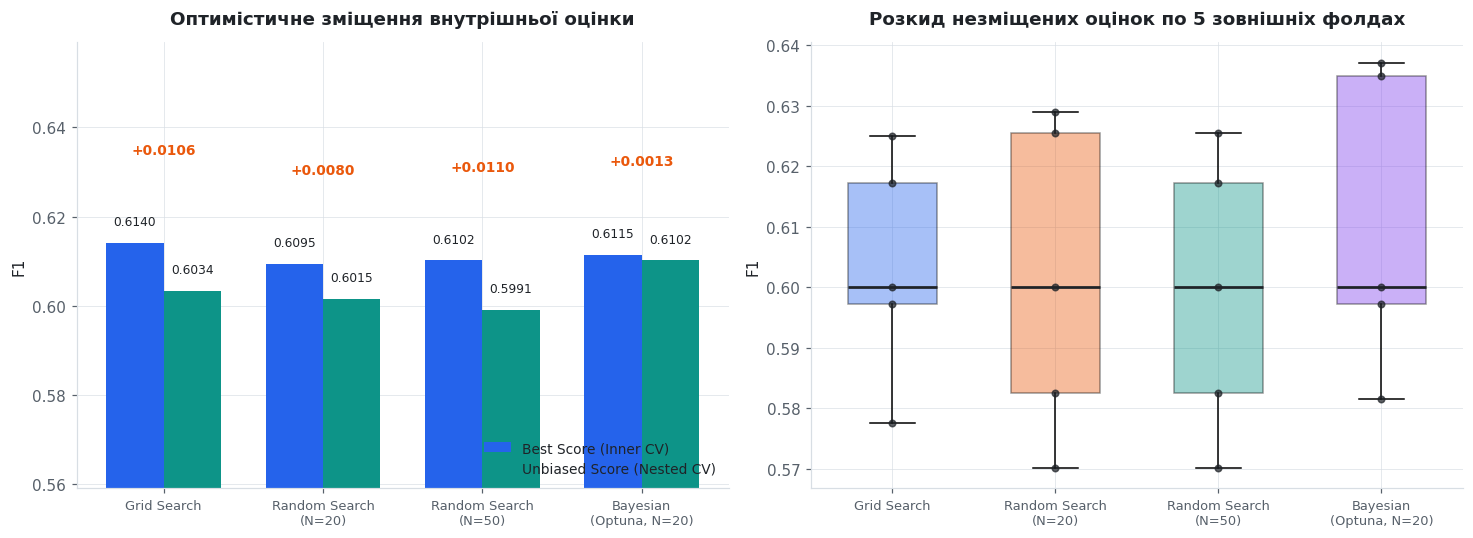

Середній розкид між фолдами одного методу: 0.0206
Розкид середніх між методами:              0.0041
Відношення: 5.0

Розкид усередині методу перевищує різницю між методами:
за якістю методи нерозрізненні, тож обирати треба за часом.


In [29]:
# --- Розкид зовнішніх фолдів і зміщення внутрішньої оцінки ---
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
names = list(NESTED)
short = [n.replace(" (", "\n(") for n in names]

# Ліва панель: внутрішня проти незміщеної
ax = axes[0]
x = np.arange(len(names)); w = 0.36
inner = [NESTED[n]["Внутрішні"].mean() for n in names]
outer = [NESTED[n]["Зовнішні"].mean() for n in names]
ax.bar(x - w / 2, inner, w, label="Best Score (Inner CV)", color=PALETTE[0])
ax.bar(x + w / 2, outer, w, label="Unbiased Score (Nested CV)", color=PALETTE[2])
for xi, (a, b) in enumerate(zip(inner, outer)):
    ax.text(xi - w / 2, a + 0.004, f"{a:.4f}", ha="center", fontsize=8, color=INK)
    ax.text(xi + w / 2, b + 0.004, f"{b:.4f}", ha="center", fontsize=8, color=INK)
    ax.annotate(f"{a - b:+.4f}", (xi, max(a, b) + 0.020), ha="center",
                fontsize=9, color=PALETTE[1], fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(short, fontsize=8.5)
ax.set_ylim(min(outer) - 0.04, max(inner) + 0.045)
ax.legend(fontsize=9, loc="lower right")
style_axes(ax, "Оптимістичне зміщення внутрішньої оцінки", "", "F1")

# Права панель: розподіл зовнішніх оцінок по фолдах
ax = axes[1]
data = [NESTED[n]["Зовнішні"] for n in names]
bp = ax.boxplot(data, tick_labels=short, patch_artist=True, widths=0.55)
for patch, n in zip(bp["boxes"], names):
    patch.set_facecolor(method_color(n)); patch.set_alpha(0.40)
for med in bp["medians"]:
    med.set_color(INK); med.set_linewidth(1.8)
# Показуємо кожен фолд окремою точкою
for i, d in enumerate(data, 1):
    ax.scatter(np.full(len(d), i), d, color=INK, s=18, zorder=3, alpha=0.7)
ax.tick_params(axis="x", labelsize=8.5)
style_axes(ax, "Розкид незміщених оцінок по 5 зовнішніх фолдах", "", "F1")

plt.tight_layout()
plt.show()

# Дві міри розкиду: всередині одного методу (між його фолдами)
# і між методами. Їхнє відношення вирішує, чи різниця методів значуща.
spread_within = np.mean([NESTED[n]["Зовнішні"].std() for n in names])
spread_between = np.std([NESTED[n]["Зовнішні"].mean() for n in names])
print(f"Середній розкид між фолдами одного методу: {spread_within:.4f}")
print(f"Розкид середніх між методами:              {spread_between:.4f}")
print(f"Відношення: {spread_within / spread_between:.1f}")
if spread_within > spread_between:
    print("\nРозкид усередині методу перевищує різницю між методами:")
    print("за якістю методи нерозрізненні, тож обирати треба за часом.")
else:
    print("\nРізниця між методами перевищує розкид між фолдами:")
    print("відмінність у якості є значущою.")


### Комірка 4.5 – стабільність обраних гіперпараметрів

Останній зріз, який дає вкладена схема безкоштовно: кожен зовнішній фолд обирав
гіперпараметри незалежно, тож ми маємо п'ять незалежних «найкращих» конфігурацій
замість однієї.

Якщо вони різні – а так буває майже завжди – це означає, що поняття «найкращі
гіперпараметри» саме по собі хистке: воно залежить від того, які рядки випадково
потрапили в навчальну частину. Для кожного параметра рахуємо, скільки разів
перемагало кожне його значення. Параметр, у якого один варіант виграє в усіх
п'яти фолдах, справді важливий; параметр, у якого перемоги розподілені рівномірно,
можна фіксувати довільно.

In [30]:
# --- Стабільність вибору гіперпараметрів по зовнішніх фолдах ---
# Беремо найдорожчий метод: якщо вже повний перебір нестабільний,
# то решта методів тим паче.
REF_METHOD = "Grid Search"
# Кожен рядок – незалежно обрана "найкраща" конфігурація одного фолда.
chosen = pd.DataFrame(NESTED[REF_METHOD]["Обрані"])
chosen.insert(0, "Зовнішній фолд", range(1, len(chosen) + 1))
chosen["Незміщений F1"] = NESTED[REF_METHOD]["Зовнішні"].round(4)
display(chosen)

# Для кожного параметра: як часто перемагало кожне значення
# Зрізи по стовпцях: columns[1:-1] – лише гіперпараметри,
# без службового номера фолда й без підсумкової метрики.
rows = []
for col in chosen.columns[1:-1]:
    counts = chosen[col].value_counts()      # як часто перемагало значення
    rows.append({
        "Гіперпараметр": col,
        "Різних значень обрано": chosen[col].nunique(),
        "Найчастіше значення": counts.index[0],
        "Разів із 5": int(counts.iloc[0]),
        "Стабільність": "висока" if counts.iloc[0] >= 4
                        else ("середня" if counts.iloc[0] == 3 else "низька"),
    })
stability = pd.DataFrame(rows)
display(stability)

n_identical = sum(1 for c in chosen.columns[1:-1] if chosen[c].nunique() == 1)
print(f"Метод-еталон: {REF_METHOD}")
print(f"Параметрів, однакових у всіх 5 фолдах: {n_identical} з {len(stability)}")
print(f"Унікальних конфігурацій серед 5 фолдів: "
      f"{chosen[list(chosen.columns[1:-1])].drop_duplicates().shape[0]}")
print(f"\nРозмах незміщеного F1 по фолдах: "
      f"{NESTED[REF_METHOD]['Зовнішні'].min():.4f} … "
      f"{NESTED[REF_METHOD]['Зовнішні'].max():.4f}")
print("\nЧим більше різних конфігурацій перемагає на різних фолдах, тим менше")
print("підстав вважати одну з них істинно найкращою: вибір значною мірою")
print("визначається випадковим складом навчальної частини.")


,Зовнішній фолд,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,Незміщений F1
0,1,0.0,0.1,50,31,50,0.6173
1,2,0.0,0.1,100,15,50,0.5776
2,3,1.0,0.1,50,15,50,0.5973
3,4,1.0,0.1,50,31,20,0.6250
4,5,0.0,0.2,100,15,20,0.6000


,Гіперпараметр,Різних значень обрано,Найчастіше значення,Разів із 5,Стабільність
0,l2_regularization,2,0.0,3,середня
1,learning_rate,2,0.1,4,висока
2,max_iter,2,50.0,3,середня
3,max_leaf_nodes,2,15.0,3,середня
4,min_samples_leaf,2,50.0,3,середня


Метод-еталон: Grid Search
Параметрів, однакових у всіх 5 фолдах: 0 з 5
Унікальних конфігурацій серед 5 фолдів: 5

Розмах незміщеного F1 по фолдах: 0.5776 … 0.6250

Чим більше різних конфігурацій перемагає на різних фолдах, тим менше
підстав вважати одну з них істинно найкращою: вибір значною мірою
визначається випадковим складом навчальної частини.


---
# Розділ 5. Підсумковий звіт

**Вимоги методички до звіту:** порівняльна таблиця методів оптимізації,
порівняння витоку даних, графік «якість / час обчислень» та висновки щодо
доцільності вибору методу за обмежених обчислювальних ресурсів.

Перші три складові вже отримані в розділах 2–4. Цей розділ зводить їх докупи,
навчає остаточну конфігурацію на **повній** навчальній вибірці й перевіряє її на
тестовому 2017 році, якого не торкався жоден експеримент роботи.

Жодне число в розділі не вписане вручну: усі значення беруться з обчислених вище
об'єктів.

### Комірка 5.1 – підсумкова порівняльна таблиця методів оптимізації

Та сама таблиця, що в комірці 2.5, але тепер із заповненим стовпцем
**Unbiased Score (Nested CV)**. Це головний числовий результат роботи: він
показує одночасно, скільки коштує кожен метод, що він про себе повідомляє і
якої якості слід очікувати насправді.

Стовпець «Підвибірка» додано для чесності: однорівневий пошук виконувався на
більшому обсязі, ніж вкладена крос-валідація, тому дві оцінки якості не можна
зіставляти напряму. Пряме зіставлення на однакових даних зроблено в комірці 4.3.

In [31]:
# --- Підсумкова порівняльна таблиця (головна вимога методички) ---
# Таблиця у форматі, якого прямо вимагає методичка: метод, кількість
# оцінок, час, Best Score (Inner CV) і Unbiased Score (Nested CV).
final_table = pd.DataFrame([
    {"Метод оптимізації": name,
     "Кількість ітерацій / оцінок": SEARCH_RESULTS[name]["Оцінок"],
     "Час виконання, с": round(SEARCH_RESULTS[name]["Час, с"], 1),
     "Best Score (Inner CV)": round(SEARCH_RESULTS[name]["Best Score (Inner CV)"], 4),
     "Unbiased Score (Nested CV)": round(NESTED[name]["Зовнішні"].mean(), 4),
     "Час вкладеної CV, хв": round(NESTED[name]["Час, с"] / 60, 1),
     "Підвибірка пошуку / вкладеної CV": f"{N_OPT} / {N_NESTED}"}
    for name in SEARCH_RESULTS
])
display(final_table)

print("Пояснення стовпців:")
print("  Best Score (Inner CV)      – що метод повідомляє про себе сам;")
print("  Unbiased Score (Nested CV) – якість, підтверджена на даних,")
print("                               які у виборі гіперпараметрів не брали участі.\n")

# Переможці за двома критеріями: якість і вартість. Якщо це різні методи,
# вибір між ними й визначається наявними обчислювальними ресурсами.
i_q = final_table["Unbiased Score (Nested CV)"].idxmax()
i_t = final_table["Час виконання, с"].idxmin()
print(f"Найвища незміщена якість: {final_table.loc[i_q, 'Метод оптимізації']} "
      f"({final_table.loc[i_q, 'Unbiased Score (Nested CV)']:.4f})")
print(f"Найдешевший метод:        {final_table.loc[i_t, 'Метод оптимізації']} "
      f"({final_table.loc[i_t, 'Час виконання, с']:.0f} с)")
print(f"Різниця незміщеної якості між найкращим і найгіршим методом: "
      f"{final_table['Unbiased Score (Nested CV)'].max() - final_table['Unbiased Score (Nested CV)'].min():.4f}")
print(f"Різниця часу між найдорожчим і найдешевшим:                  "
      f"{final_table['Час виконання, с'].max() / final_table['Час виконання, с'].min():.1f} разів")


,Метод оптимізації,Кількість ітерацій / оцінок,"Час виконання, с",Best Score (Inner CV),Unbiased Score (Nested CV),"Час вкладеної CV, хв",Підвибірка пошуку / вкладеної CV
0,Grid Search,108,577.1,0.6219,0.6034,18.8,12000 / 3000
1,Random Search (N=20),20,99.3,0.6148,0.6015,3.2,12000 / 3000
2,Random Search (N=50),50,294.1,0.6189,0.5991,9.3,12000 / 3000
3,"Bayesian (Optuna, N=20)",20,93.6,0.6148,0.6102,2.6,12000 / 3000


Пояснення стовпців:
  Best Score (Inner CV)      – що метод повідомляє про себе сам;
  Unbiased Score (Nested CV) – якість, підтверджена на даних,
                               які у виборі гіперпараметрів не брали участі.

Найвища незміщена якість: Bayesian (Optuna, N=20) (0.6102)
Найдешевший метод:        Bayesian (Optuna, N=20) (94 с)
Різниця незміщеної якості між найкращим і найгіршим методом: 0.0111
Різниця часу між найдорожчим і найдешевшим:                  6.2 разів


### Комірка 5.2 – остаточна конфігурація і навчання на повній вибірці

Остаточні гіперпараметри обираємо за **незміщеною** оцінкою: метод із найкращим
Unbiased Score, а в ньому – конфігурація, знайдена однорівневим пошуком розділу 2.

Далі робимо те, заради чого вся робота й велася: навчаємо коректний пайплайн на
**повній** навчальній вибірці 2007–2015 років. Підвибірки потрібні були лише для
пошуку; остаточна модель бачить усі дані.

Для порівняння так само навчаємо baseline із гіперпараметрами за замовчуванням.
Різниця між ними на валідаційному 2016 році й показує реальну цінність
оптимізації – уже без будь-яких підвибірок і внутрішніх оцінок.

In [32]:
# --- Остаточна конфігурація за незміщеною оцінкою ---
# Метод обираємо за НЕЗМІЩЕНОЮ оцінкою, а не за тією, яку пошук
# повідомив про себе сам, – саме в цьому сенс розділу 4.
BEST_METHOD = max(NESTED, key=lambda n: NESTED[n]["Зовнішні"].mean())
# Самі гіперпараметри беремо з однорівневого пошуку розділу 2: він
# виконувався на більшій підвибірці, тож його вибір надійніший.
BEST_PARAMS = {k.replace("model__", ""): v
               for k, v in SEARCH_RESULTS[BEST_METHOD]["Найкращі гіперпараметри"].items()}

print(f"Метод-переможець:  {BEST_METHOD}")
print(f"  незміщена оцінка: {NESTED[BEST_METHOD]['Зовнішні'].mean():.4f}")
print(f"Остаточні гіперпараметри:")
for k, v in sorted(BEST_PARAMS.items()):
    print(f"  {k:<20} = {v}")

# --- Навчання на ПОВНІЙ навчальній вибірці 2007-2015 ---
print(f"\nНавчання на повній вибірці {len(df_train):,} рядків …".replace(",", " "))

t0 = time.time()
final_model = make_pipeline(**BEST_PARAMS).fit(df_train, y_train)
t_final = time.time() - t0

t0 = time.time()
base_model = make_pipeline().fit(df_train, y_train)      # гіперпараметри за замовчуванням
t_base = time.time() - t0

def evaluate(model, frame, y_true):
    """Повний набір метрик однієї моделі на одній вибірці."""
    # [:, 1] – імовірність саме позитивного класу (дощ наступного дня)
    proba = model.predict_proba(frame)[:, 1]
    # Поріг 0,5 – стандартний; його підбір був темою ЛР №2 і тут не повторюється
    pred = (proba >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, proba),
            "PR-AUC": average_precision_score(y_true, proba)}

# Кожну модель оцінюємо один раз, результати зберігаємо – далі вони
# знадобляться ще й у комірці 5.3.
valid_base_m = evaluate(base_model, df_valid, y_valid)
valid_final_m = evaluate(final_model, df_valid, y_valid)

valid_cmp = pd.DataFrame({
    "Метрика": list(valid_base_m),
    "Baseline (за замовчуванням)": list(valid_base_m.values()),
    "Оптимізована конфігурація": list(valid_final_m.values()),
})
valid_cmp["Приріст"] = (valid_cmp["Оптимізована конфігурація"]
                        - valid_cmp["Baseline (за замовчуванням)"])
display(valid_cmp.round(4))

print(f"Час навчання: baseline {t_base:.1f} с, оптимізована {t_final:.1f} с")
print(f"\nПриріст F1 на валідації 2016: "
      f"{valid_cmp.loc[valid_cmp['Метрика'] == 'F1', 'Приріст'].iloc[0]:+.4f}")
print("Це і є реальна цінність оптимізації – без підвибірок і внутрішніх оцінок.")


Метод-переможець:  Bayesian (Optuna, N=20)
  незміщена оцінка: 0.6102
Остаточні гіперпараметри:
  l2_regularization    = 1.0
  learning_rate        = 0.1
  max_iter             = 100
  max_leaf_nodes       = 63
  min_samples_leaf     = 50

Навчання на повній вибірці 116 219 рядків …


,Метрика,Baseline (за замовчуванням),Оптимізована конфігурація,Приріст
0,Accuracy,0.8464,0.8491,0.0027
1,Precision,0.7373,0.7404,0.0031
2,Recall,0.5549,0.5673,0.0124
3,F1,0.6332,0.6424,0.0092
4,ROC-AUC,0.8768,0.8814,0.0046
5,PR-AUC,0.7393,0.7456,0.0063


Час навчання: baseline 11.0 с, оптимізована 33.1 с

Приріст F1 на валідації 2016: +0.0092
Це і є реальна цінність оптимізації – без підвибірок і внутрішніх оцінок.


### Комірка 5.3 – фінальна оцінка на тестовій вибірці 2017 року

Останній і єдиний дозволений дотик до тестових даних. Вибірка 2017 року була
відокремлена ще в комірці 1.2 й не брала участі ані в пошуку гіперпараметрів, ані
у вкладеній крос-валідації, ані у виборі остаточної конфігурації.

Порівнюємо три числа: обіцянку внутрішньої крос-валідації, незміщену оцінку
вкладеної схеми та фактичний результат на 2017 році. Чим ближче друге число до
третього, тим краще вкладена схема впоралася зі своїм завданням – саме це й
перевіряється.

Зниження метрик відносно валідації очікуване й не є ознакою перенавчання: 2017 рік
відділений від навчального періоду більшим проміжком часу, ніж 2016-й.

In [33]:
# --- Фінальна оцінка на незалежній тестовій вибірці 2017 ---
# Перший і єдиний дотик до тестових даних за всю роботу
test_base  = evaluate(base_model, df_test, y_test)
test_final = evaluate(final_model, df_test, y_test)
valid_final = valid_final_m          # уже обчислено в комірці 5.2

test_cmp = pd.DataFrame({
    "Метрика": list(test_base),
    "Baseline (тест 2017)": list(test_base.values()),
    "Оптимізована (тест 2017)": list(test_final.values()),
    "Оптимізована (валідація 2016)": list(valid_final.values()),
})
test_cmp["Приріст від оптимізації"] = (test_cmp["Оптимізована (тест 2017)"]
                                       - test_cmp["Baseline (тест 2017)"])
test_cmp["Зміна 2016 -> 2017"] = (test_cmp["Оптимізована (тест 2017)"]
                                  - test_cmp["Оптимізована (валідація 2016)"])
display(test_cmp.round(4))

# --- Три оцінки одного й того самого: що обіцяли і що вийшло ---
# Усі чотири рядки стосуються ОДНІЄЇ моделі з однаковими гіперпараметрами;
# різниця лише в тому, на яких даних і за яким протоколом її оцінювали.
f1_test = test_final["F1"]
promise = pd.DataFrame({
    "Джерело оцінки": ["Внутрішня CV (розділ 2)",
                       "Вкладена CV (розділ 4)",
                       "Валідація 2016",
                       "Тест 2017 (факт)"],
    "F1": [SEARCH_RESULTS[BEST_METHOD]["Best Score (Inner CV)"],
           NESTED[BEST_METHOD]["Зовнішні"].mean(),
           valid_final["F1"],
           f1_test],
})
promise["Відхилення від факту"] = (promise["F1"] - f1_test)
display(promise.round(4))

print(f"Фактичний F1 на тесті 2017: {f1_test:.4f}")
print(f"  переоцінка внутрішньою CV:  "
      f"{promise.loc[0, 'Відхилення від факту']:+.4f}")
print(f"  відхилення вкладеної CV:    "
      f"{promise.loc[1, 'Відхилення від факту']:+.4f}")

if abs(promise.loc[1, "Відхилення від факту"]) < abs(promise.loc[0, "Відхилення від факту"]):
    print("\nВкладена крос-валідація виявилася ближчою до факту, ніж внутрішня –")
    print("саме цього від неї й очікували.")
else:
    print("\nОбидві оцінки відхилилися від факту; на відстані в рік відхилення")
    print("визначається вже не протоколом, а зміною самих даних.")


,Метрика,Baseline (тест 2017),Оптимізована (тест 2017),Оптимізована (валідація 2016),Приріст від оптимізації,Зміна 2016 -> 2017
0,Accuracy,0.8623,0.8633,0.8491,0.0011,0.0142
1,Precision,0.7445,0.7432,0.7404,-0.0013,0.0028
2,Recall,0.5156,0.5252,0.5673,0.0096,-0.0421
3,F1,0.6092,0.6155,0.6424,0.0062,-0.0269
4,ROC-AUC,0.8788,0.8820,0.8814,0.0033,0.0007
5,PR-AUC,0.7118,0.7179,0.7456,0.0062,-0.0276


,Джерело оцінки,F1,Відхилення від факту
0,Внутрішня CV (розділ 2),0.6148,-0.0007
1,Вкладена CV (розділ 4),0.6102,-0.0053
2,Валідація 2016,0.6424,0.0269
3,Тест 2017 (факт),0.6155,0.0000


Фактичний F1 на тесті 2017: 0.6155
  переоцінка внутрішньою CV:  -0.0007
  відхилення вкладеної CV:    -0.0053

Обидві оцінки відхилилися від факту; на відстані в рік відхилення
визначається вже не протоколом, а зміною самих даних.


### Комірка 5.4 – зведена таблиця ключових результатів

Остання таблиця зводить усі числові підсумки роботи в одному місці. Жодне
значення не вписане вручну – усі беруться з обчислених вище об'єктів, тому
таблиця автоматично залишається узгодженою з рештою ноутбука при повторному
запуску.

In [34]:
# --- Зведення ключових числових результатів роботи ---
# Усі значення нижче беруться з уже обчислених об'єктів: жодне число
# не вписане вручну, тож таблиця не розійдеться з рештою ноутбука.
best_search = max(SEARCH_RESULTS.values(), key=lambda r: r["Best Score (Inner CV)"])
cheapest = min(SEARCH_RESULTS, key=lambda n: SEARCH_RESULTS[n]["Час, с"])
total_evals = sum(r["Оцінок"] for r in SEARCH_RESULTS.values())
total_search_time = sum(r["Час, с"] for r in SEARCH_RESULTS.values())
total_nested_time = sum(r["Час, с"] for r in NESTED.values())

summary = pd.DataFrame([
    ("Дані", "Робоча вибірка, рядків", f"{len(df):,}".replace(",", " ")),
    ("Дані", "Навчальна / валідаційна / тестова",
     f"{len(df_train):,} / {len(df_valid):,} / {len(df_test):,}".replace(",", " ")),
    ("Дані", "Ознак після обробки", f"{Z_train.shape[1]}"),
    ("Дані", "Підвибірка пошуку / вкладеної CV",
     f"{N_OPT:,} / {N_NESTED:,}".replace(",", " ")),

    ("Модель", "Алгоритм", MODEL_NAME),
    ("Модель", "Головна метрика", "F1-score"),
    ("Модель", "Гіперпараметрів у просторі", f"{len(PARAM_GRID)}"),
    ("Модель", "Розмір повного простору", f"{GRID_SIZE} комбінацій"),

    ("Етап 2", "Усього оцінок гіперпараметрів", f"{total_evals}"),
    ("Етап 2", "Сумарний час пошуку, с", f"{total_search_time:.0f}"),
    ("Етап 2", "Baseline F1 (внутрішня CV)", f"{BASELINE_F1:.4f}"),
    ("Етап 2", "Найкращий F1 (внутрішня CV)",
     f"{best_search['Best Score (Inner CV)']:.4f}"),
    ("Етап 2", "Приріст від оптимізації",
     f"{best_search['Best Score (Inner CV)'] - BASELINE_F1:+.4f}"),
    ("Етап 2", "Найдешевший метод", cheapest),

    ("Етап 3", "F1 за коректного протоколу", f"{m_correct['F1']:.4f}"),
    ("Етап 3", "F1 за протоколу з витоком", f"{m_leaky['F1']:.4f}"),
    ("Етап 3", "Штучне завищення F1", f"{f1_gain:+.4f}"),
    ("Етап 3", "Внесок цільового кодування",
     f"{sources.loc[1, 'Завищення F1']:+.4f}"),
    ("Етап 3", "Внесок статистик ознак",
     f"{sources.loc[2, 'Завищення F1']:+.4f}"),

    ("Етап 4", "Схема вкладеної CV",
     f"зовнішня K={OUTER_CV.get_n_splits()}, внутрішня K={INNER_CV.get_n_splits()}"),
    ("Етап 4", "Час вкладеної CV, хв", f"{total_nested_time / 60:.1f}"),
    ("Етап 4", "Найбільше зміщення внутрішньої оцінки",
     f"{nested_tbl['Зміщення'].max():+.4f}"),
    ("Етап 4", "Найкраща незміщена оцінка",
     f"{nested_tbl['Unbiased Score (Nested CV)'].max():.4f}"),
    ("Етап 4", "Середній розкид між зовнішніми фолдами", f"{spread_within:.4f}"),

    ("Підсумок", "Метод-переможець", BEST_METHOD),
    ("Підсумок", "Остаточні гіперпараметри",
     ", ".join(f"{k}={v}" for k, v in sorted(BEST_PARAMS.items()))),
    ("Підсумок", "F1 на валідації 2016", f"{valid_final['F1']:.4f}"),
    ("Підсумок", "F1 на тесті 2017", f"{f1_test:.4f}"),
    ("Підсумок", "PR-AUC на тесті 2017", f"{test_final['PR-AUC']:.4f}"),
    ("Підсумок", "Приріст F1 над baseline на тесті",
     f"{test_final['F1'] - test_base['F1']:+.4f}"),
], columns=["Розділ", "Показник", "Значення"])

pd.set_option("display.max_rows", 60)
display(summary)
print(f"Усього показників: {len(summary)}")


,Розділ,Показник,Значення
0,Дані,"Робоча вибірка, рядків",142 193
1,Дані,Навчальна / валідаційна / тестова,116 219 / 17 508 / 8 466
2,Дані,Ознак після обробки,74
3,Дані,Підвибірка пошуку / вкладеної CV,12 000 / 3 000
4,Модель,Алгоритм,HistGradientBoostingClassifier
5,Модель,Головна метрика,F1-score
6,Модель,Гіперпараметрів у просторі,5
7,Модель,Розмір повного простору,108 комбінацій
8,Етап 2,Усього оцінок гіперпараметрів,198
9,Етап 2,"Сумарний час пошуку, с",1064


Усього показників: 30


### Комірка 5.5 – збереження артефактів

Зберігаємо таблиці й модель, щоб результати можна було використати у звіті й не
перезапускати ноутбук заново. У Google Colab файли з'являються в теці `/content`
і залишаються доступними до завершення сеансу.

In [35]:
# --- Збереження артефактів ---
OUT_DIR = Path("lab3_output")
OUT_DIR.mkdir(exist_ok=True)

# utf-8-sig (з BOM) – щоб Excel коректно відкрив кирилицю без зайвих налаштувань
tables = {
    "01_порівняння_методів": final_table,
    "02_витік_даних": leak_table,
    "03_джерела_витоку": sources,
    "04_вплив_гіперпараметрів": influence,
    "05_вкладена_CV": nested_tbl,
    "06_стабільність_вибору": chosen,
    "07_оцінка_на_тесті": test_cmp,
    "08_зведення_результатів": summary,
}
for name, tbl in tables.items():
    tbl.to_csv(OUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

# Остаточну конфігурацію зберігаємо окремо у форматі JSON:
# її достатньо, щоб відтворити модель без ноутбука.
config = {
    "model": MODEL_NAME,
    "metric": PRIMARY_METRIC,
    "best_method": BEST_METHOD,
    "best_params": {k: (int(v) if isinstance(v, (int, np.integer)) else float(v))
                    for k, v in BEST_PARAMS.items()},
    "inner_cv_score": float(SEARCH_RESULTS[BEST_METHOD]["Best Score (Inner CV)"]),
    "nested_cv_score": float(NESTED[BEST_METHOD]["Зовнішні"].mean()),
    "valid_2016_f1": float(valid_final["F1"]),
    "test_2017_f1": float(f1_test),
    "random_state": RANDOM_STATE,
}
(OUT_DIR / "final_config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

# Навчена модель разом з усім конвеєром обробки: joblib зберігає
# і перетворювачі, і саму модель, тож її можна застосувати до сирих даних.
try:
    import joblib
    joblib.dump(final_model, OUT_DIR / "final_model.joblib")
    model_saved = True
except Exception as e:
    model_saved = False
    print(f"Модель не збережено: {e}")

print(f"Артефакти збережено у теку: {OUT_DIR.resolve()}\n")
for f in sorted(OUT_DIR.iterdir()):
    print(f"  {f.name:<34} {f.stat().st_size / 1024:7.1f} КБ")

print(f"\nТаблиць: {len(tables)}, модель збережено: {'так' if model_saved else 'ні'}")
print("\nЛабораторну роботу №3 виконано.")


Артефакти збережено у теку: /content/lab3_output

  01_порівняння_методів.csv              0.5 КБ
  02_витік_даних.csv                     0.4 КБ
  03_джерела_витоку.csv                  0.6 КБ
  04_вплив_гіперпараметрів.csv           0.2 КБ
  05_вкладена_CV.csv                     0.4 КБ
  06_стабільність_вибору.csv             0.2 КБ
  07_оцінка_на_тесті.csv                 0.8 КБ
  08_зведення_результатів.csv            2.1 КБ
  final_config.json                      0.4 КБ
  final_model.joblib                   976.8 КБ

Таблиць: 8, модель збережено: так

Лабораторну роботу №3 виконано.
